<a href="https://colab.research.google.com/github/zunaaaaayed/Temporal-Drift-VLM/blob/main/Temporal_Drift_VLMs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Temporal Drift in Visual Embedding Spaces of Multilingual Vision-Language Models

**Author:** Md Zunayedul Islam | **Email:** mdz.islam@estudiante.uam.es | **Course:** DL4VSP2 | **Program:** IPCV | **Institution:** UAM

---

## Abstract

Contrastive vision-language models such as CLIP encode a shared image-text embedding space that is implicitly anchored to the temporal distribution of their training data. This notebook presents the first systematic study of *temporal drift* in visual embedding spaces: the phenomenon by which concepts with changing visual appearance produce systematically different image distributions across historical periods. Using 19,334 timestamped photographs from YFCC15M spanning 2004-2014, we probe 18 visual concepts across three semantic tiers with temporally-anchored prompts in six typologically diverse languages. We compare three architectures: CLIP (ViT-B/32), M-OpenCLIP (ViT-B/32), and SigLIP-2 (ViT-B/16).

---

## Hypotheses

**H1 (Concept-tier drift):** Semantic tier is an important predictor of visual distributional shift, either directly or in interaction with linguistic resources.

**H2 (Cross-lingual asymmetry):** Temporal text-direction drift is jointly predicted by language training-data volume and morphological typology. High-resource languages with lexical-substitution patterns (Japanese, Russian) produce greater query displacement than low-resource languages (Bengali, Swahili).

**H3 (Trajectory smoothness):** Consecutive centroid displacements across temporal bins are directionally more consistent than a permutation-null baseline, indicating structured concept evolution rather than random fluctuation.

---

## Drift Metrics

| Metric | Symbol | Description |
|---|---|---|
| Sliced Wasserstein Distance | SWD | Distributional divergence between full embedding clouds across temporal bins |
| Centroid Displacement | $\Delta$ | Cosine distance between L2-normalised means of two embedding clouds |
| Text Direction Drift | $\delta$ | Cosine distance between mean temporally-anchored text embeddings across bins |
| Trajectory Angle | $\theta_{\text{vis}}$ | Angle between consecutive centroid displacement vectors (smaller = more consistent) |
| MAP@k | MAP@k | Mean Average Precision at cutoff $k$ for neutral-prompt retrieval |

## Statistical Tests

| Hypothesis | Primary Test | Secondary Test |
|---|---|---|
| H1 | Linear Mixed-Effects Model (LME) | Paired permutation test + Cohen's $d$ |
| H2 | Spearman rank correlation | LME: $\delta \sim \log(\text{resource})$ |
| H3 | Wilcoxon signed-rank test | Permutation null from 1,000 bin-label shuffles |

Significance threshold: $\alpha = 0.05$ for all tests.


## 1. Environment Setup

All package versions are pinned to ensure reproducibility. The environment was tested on Google Colab with a Tesla T4 GPU (CUDA 12.x, Python 3.11).

In [ ]:
!pip install -q aiohttp==3.13.4 nest_asyncio==1.6.0 datasets==4.0.0 regex==2025.11.3
!pip install -q tqdm==4.67.3 pandas==2.2.2 matplotlib==3.10.0 seaborn==0.13.2 pingouin==0.6.1
!pip install -q transformers==5.0.0 sentencepiece==0.2.1 ftfy==6.3.1 scikit-learn==1.6.1
!pip install -q umap-learn==0.5.11 sentence-transformers==5.3.0 timm==1.0.26 POT==0.9.6.post1
!pip install -q statsmodels==0.14.6 codecarbon==3.2.6 opencv-python-headless==4.13.0.92 open-clip-torch==3.3.0

print("All necessary dependencies installed.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.0/204.0 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.2/40.2 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.9/90.9 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 512.4/512.4 kB 28.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 59.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 380.8/380.8 kB 22.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 38.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.6/155.6 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 73.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 48.0 MB/s eta 0:00:00
All necessary dependencies installed.


## 2. Imports

In [ ]:
import os
import re
import sys
import glob
import random
import warnings
import itertools
import importlib

import aiohttp
import asyncio
import nest_asyncio
from tqdm import tqdm
from tqdm.asyncio import tqdm as atqdm
from IPython.display import display
from codecarbon import EmissionsTracker

import pandas as pd
import numpy as np
import ot
import pingouin as pg
import statsmodels.formula.api as smf
from scipy.stats import wilcoxon, spearmanr, ttest_rel
from sklearn.decomposition import PCA
import umap as umap_lib

import cv2
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import open_clip
from datasets import load_dataset
from transformers import CLIPProcessor, CLIPModel, AutoModel, AutoProcessor
from sentence_transformers import SentenceTransformer

from huggingface_hub import login
from google.colab import userdata, drive


warnings.filterwarnings("ignore")
drive.mount("/content/drive")
hf_token = userdata.get('HF_TOKEN')
login(token=hf_token)
print("Successfully logged in to HuggingFace Hub.")
print("All necessary libraries imported.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Successfully logged in to HuggingFace Hub.
All necessary libraries imported.


## 3. Global Configuration

The `CONFIG` dictionary centralises all experimental hyperparameters.

**Languages and mC4 resource levels** (approximate token counts by Xue et al. [2021]):

| Language | Code | mC4 tokens |
|---|---|---|
| English | `en` | ~400B |
| Russian | `ru` | ~80B |
| Japanese | `ja` | ~40B |
| Arabic | `ar` | ~10B |
| Bengali | `bn` | ~1B |
| Swahili | `sw` | ~0.3B |

**Models compared:**

| Model | Architecture | Training corpus | Embedding dim |
|---|---|---|---|
| CLIP | ViT-B/32 | WebImageText (~400M pairs) | 512 |
| M-OpenCLIP | ViT-B/32 | LAION-5B | 512 |
| SigLIP-2 | ViT-B/16 | Multilingual (sigmoid loss) | 768 |

**Concept tiers** are assigned a priori based on expected visual change during 2004-2014. Two misclassifications become apparent in the results: *surgery* (labeled slow-drift) exhibits the largest visual distributional shift in the dataset, and *protest* (labeled fast-drift) produces a near-random centroid trajectory.

In [ ]:
WORK_DIR    = "/content/drive/MyDrive/DL4VSP2Project"
META_DIR    = os.path.join(WORK_DIR, "metadata")
EMBED_DIR   = os.path.join(WORK_DIR, "embeddings")
IMAGES_DIR  = os.path.join(WORK_DIR, "images")
RESULTS_DIR = os.path.join(WORK_DIR, "results")

for d in [META_DIR, EMBED_DIR, IMAGES_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

device   = "cuda" if torch.cuda.is_available() else "cpu"
gpu_name = torch.cuda.get_device_name(0) if device == "cuda" else "CPU"
print(f"Device: {device} | {gpu_name}")
print(f"Work dir: {WORK_DIR}")

CONFIG = {
    "languages"     : ["en", "ru", "ja", "ar", "bn", "sw"],
    "temporal_bins" : ["pre2008", "2008_2011", "2012_2014"],
    "k_values"      : [10, 50],
    "n_proj_swd"    : 200,
    "n_permutations": 1000,
    "target_per_bin": 400,

    "models": {
        "clip": {
            "type"         : "hf",
            "name"         : "openai/clip-vit-base-patch32",
            "file_prefix"  : "clip_vitb32",
            "embedding_dim": 512,
        },
        "m_openclip": {
            "type"         : "oc_ml",
            "name"         : "xlm-roberta-base-ViT-B-32",
            "pretrained"   : "laion5b_s13b_b90k",
            "file_prefix"  : "m_openclip_vitb32",
            "embedding_dim": 512,
        },
        "siglip2": {
            "type"         : "siglip2",
            "name"         : "google/siglip2-base-patch16-256",
            "file_prefix"  : "siglip2_ml",
            "embedding_dim": 768,
        },
    },

    "concepts": [
        "mountain", "river",   "ocean",      "forest",     "beach",   "moon",
        "hospital", "office",  "classroom",  "restaurant", "library", "surgery",
        "phone",    "protest", "television", "computer",   "camera",  "car",
    ],
    "concept_tiers": {
        "stable": ["mountain", "river", "ocean", "forest", "beach", "moon"],
        "slow"  : ["hospital", "office", "classroom", "restaurant", "library", "surgery"],
        "fast"  : ["phone", "protest", "television", "computer", "camera", "car"],
    },

    "resource_level": {
        "en": 400e9,
        "ru": 80e9,
        "ja": 40e9,
        "ar": 10e9,
        "bn": 1e9,
        "sw": 0.3e9,
    },
}

TIER_MAP  = {c: t for t, cs in CONFIG["concept_tiers"].items() for c in cs}
MODEL_DIM = {mk: mv["embedding_dim"] for mk, mv in CONFIG["models"].items()}

print(f"Languages : {CONFIG['languages']}  ({len(CONFIG['languages'])} total)")
print(f"Concepts  : {len(CONFIG['concepts'])} total — "
      f"{len(CONFIG['concept_tiers']['stable'])} stable, "
      f"{len(CONFIG['concept_tiers']['slow'])} slow, "
      f"{len(CONFIG['concept_tiers']['fast'])} fast")
print(f"Models    : {list(CONFIG['models'].keys())}  dims={MODEL_DIM}")

print("Configuration loaded.")

Device: cuda | Tesla T4
Work dir: /content/drive/MyDrive/DL4VSP2Project
Languages : ['en', 'ru', 'ja', 'ar', 'bn', 'sw']  (6 total)
Concepts  : 18 total — 6 stable, 6 slow, 6 fast
Models    : ['clip', 'm_openclip', 'siglip2']  dims={'clip': 512, 'm_openclip': 512, 'siglip2': 768}
Configuration loaded.


## 4. Reproducibility

Global random seed is set to 42 for all stochastic operations (NumPy, PyTorch, Python's `random` module, and `PYTHONHASHSEED`). All embeddings are cached to Google Drive so that the full pipeline can be resumed without re-encoding.

In [ ]:
def set_seed(seed: int = 42):
    # Fixes all sources of randomness for reproducibility.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(42)
print("Seed set to 42.")

Seed set to 42.


---

# Section I: Data Pipeline

The data pipeline proceeds in five stages:

1. **Detection** - Identify which concepts require image acquisition.
2. **Streaming** - Pull matching YFCC15M records using a 2D quota system.
3. **Download** - Asynchronously download Flickr images.
4. **Extraction** - Encode images with each vision model and cache embeddings.
5. **Verification** - Confirm all artifacts are present and L2-normalised.

**Dataset:** YFCC100M (Thomee et al., 2016), accessed via the `mehdidc/yfcc15m` HuggingFace streaming split. Records are matched to concept keywords in the title and description fields. Temporal binning uses the Flickr upload date as a proxy for capture date.

**Temporal bins:**

| Bin | Period | Rationale |
|---|---|---|
| `pre2008` | Before 2008 | Pre-smartphone-mass-market era |
| `2008_2011` | 2008-2011 | iPhone introduction (2007) and Android ecosystem rise |
| `2012_2014` | 2012-2014 | Post-smartphone convergence; YFCC coverage end |

The bins are unequal in length; this asymmetry is inherent to YFCC's temporal composition (Flickr upload volumes before 2006 are substantially lower). Per-bin quota sampling mitigates the resulting image-count imbalance.

## 1.1 Missing Data Detection

In [ ]:
print("Detecting missing data\n")

TARGET = CONFIG["target_per_bin"]
bins   = CONFIG["temporal_bins"]

image_counts = {}
for c in CONFIG["concepts"]:
    image_counts[c] = {}
    for b in bins:
        p = os.path.join(IMAGES_DIR, c, b)
        image_counts[c][b] = (len(glob.glob(os.path.join(p, "*.jpg")))
                               if os.path.isdir(p) else 0)

MISSING_CONCEPTS = [
    c for c in CONFIG["concepts"]
    if any(image_counts[c][b] == 0 for b in bins)
]

print(f"{'CONCEPT':<14} | {'pre2008':>8} {'2008_2011':>10} {'2012_2014':>10} | STATUS")
print("-" * 60)
for c in CONFIG["concepts"]:
    counts = [image_counts[c][b] for b in bins]
    ok     = all(n > 0 for n in counts)
    status = "OK" if ok else "ERROR"
    print(f"  {c:<12} | {counts[0]:>8} {counts[1]:>10} {counts[2]:>10} | {status}")

print()
if not MISSING_CONCEPTS:
    print(" All concepts have images.")
else:
    print(f"  Concepts requiring streaming + download: {MISSING_CONCEPTS}")
    print(f"  Target: {TARGET} images per bin per concept")

Detecting missing data

CONCEPT        |  pre2008  2008_2011  2012_2014 | STATUS
------------------------------------------------------------
  mountain     |        0          0          0 | ERROR
  river        |        0          0          0 | ERROR
  ocean        |        0          0          0 | ERROR
  forest       |        0          0          0 | ERROR
  beach        |        0          0          0 | ERROR
  moon         |        0          0          0 | ERROR
  hospital     |        0          0          0 | ERROR
  office       |        0          0          0 | ERROR
  classroom    |        0          0          0 | ERROR
  restaurant   |        0          0          0 | ERROR
  library      |        0          0          0 | ERROR
  surgery      |        0          0          0 | ERROR
  phone        |        0          0          0 | ERROR
  protest      |        0          0          0 | ERROR
  television   |        0          0          0 | ERROR
  computer     |  

## 1.2 Image Streaming

YFCC15M is streamed in a single pass. A **2D quota system** controls acquisition: streaming halts only when all (concept, temporal bin) cells simultaneously reach their target count of 400 images, preventing chronological sampling bias that would arise from stopping as soon as the first quota is filled.

In [ ]:
if not MISSING_CONCEPTS:
    print("Streaming skipped. No missing concepts.")
else:
    csv_filtered_path = os.path.join(META_DIR, "yfcc_filtered_metadata.csv")
    TARGET = CONFIG["target_per_bin"]
    bins   = CONFIG["temporal_bins"]

    quota = {}
    for c in MISSING_CONCEPTS:
        quota[c] = {}
        for b in bins:
            have = image_counts[c][b]
            quota[c][b] = max(0, TARGET - have)

    still_needed = {c: b for c, bdict in quota.items()
                    for b, need in bdict.items() if need > 0}
    if not still_needed:
        print("Streaming skipped — quota already satisfied in existing metadata.")
    else:
        concept_regex = {c: re.compile(rf"\b{c}\b", re.IGNORECASE)
                         for c in MISSING_CONCEPTS}
        # Streaming quota: how many MORE rows we want per (concept, bin)
        stream_quota = {c: {b: TARGET for b in bins} for c in MISSING_CONCEPTS}

        # Subtract rows already in filtered CSV
        if os.path.exists(csv_filtered_path):
            df_existing_f = pd.read_csv(csv_filtered_path)
            for c in MISSING_CONCEPTS:
                for b in bins:
                    already = len(df_existing_f[
                        (df_existing_f["matched_concept"] == c) &
                        (df_existing_f["temp_bin"] == b)
                    ])
                    stream_quota[c][b] = max(0, TARGET - already)
        else:
            df_existing_f = None

        records = []
        print(f"Streaming YFCC15M for: {MISSING_CONCEPTS}")
        dataset = load_dataset("mehdidc/yfcc15m", split="train", streaming=True)

        for i, row in enumerate(dataset):
            if i % 500_000 == 0 and i > 0:
                filled  = sum(sum(b.values()) for b in stream_quota.values())
                total_t = sum(sum(bdict.values())
                              for bdict in stream_quota.values())
                remaining = sum(sum(max(0,v) for v in b.values())
                                for b in stream_quota.values())
                print(f"  Scanned {i:,} rows ({remaining} slots remaining)")

            text = (str(row.get("title", "")) + " " +
                    str(row.get("description", ""))).lower()

            for c in MISSING_CONCEPTS:
                if concept_regex[c].search(text):
                    date_taken = str(row.get("datetaken", ""))
                    year_str   = date_taken.split("-")[0] if "-" in date_taken else ""
                    if not year_str.isdigit():
                        break
                    yr = int(year_str)
                    if not (2004 <= yr <= 2014):
                        break
                    t_bin = ("pre2008"   if yr < 2008  else
                             "2008_2011" if yr <= 2011 else
                             "2012_2014")
                    if stream_quota[c][t_bin] > 0:
                        row_copy = dict(row)
                        row_copy.update({"matched_concept": c,
                                         "year": yr, "temp_bin": t_bin})
                        records.append(row_copy)
                        stream_quota[c][t_bin] -= 1
                    break

            if all(v == 0 for bdict in stream_quota.values()
                   for v in bdict.values()):
                print("\nAll quotas filled. Stream stopped.")
                break

        df_new = pd.DataFrame(records)
        print(f"\nNew metadata rows collected: {len(df_new)}")
        if len(df_new):
            print(df_new.groupby(["matched_concept", "temp_bin"])
                        .size().unstack(fill_value=0))

        # Append to existing or create
        if df_existing_f is not None and len(df_new):
            df_combined = pd.concat([df_existing_f, df_new], ignore_index=True)
        elif df_existing_f is not None:
            df_combined = df_existing_f
        else:
            df_combined = df_new

        df_combined.to_csv(csv_filtered_path, index=False)
        print(f"\nSaved: {csv_filtered_path}  ({len(df_combined)} total rows)")

Streaming YFCC15M for: ['mountain', 'river', 'ocean', 'forest', 'beach', 'moon', 'hospital', 'office', 'classroom', 'restaurant', 'library', 'surgery', 'phone', 'protest', 'television', 'computer', 'camera', 'car']


README.md:   0%|          | 0.00/381 [00:00<?, ?B/s]


All quotas filled. Stream stopped.

New metadata rows collected: 0

Saved: /content/drive/MyDrive/DL4VSP2Project/metadata/yfcc_filtered_metadata.csv  (71375 total rows)


## 1.3 Asynchronous Image Downloader

Images are downloaded from Flickr using an `asyncio`-based pipeline with a semaphore-bounded concurrency of 50 simultaneous connections. Each image is validated by checking that the downloaded content exceeds 5 KB before being written to disk.

In [ ]:
if not MISSING_CONCEPTS:
    print("Downloading skipped. No missing concepts.")
else:
    nest_asyncio.apply()

    csv_filtered_path = os.path.join(META_DIR, "yfcc_filtered_metadata.csv")
    if not os.path.exists(csv_filtered_path):
        print("No filtered metadata CSV found.")
    else:
        df_all = pd.read_csv(csv_filtered_path)
        df_to_dl = df_all[df_all["matched_concept"].isin(MISSING_CONCEPTS)].copy()
        print(f"Rows to attempt downloading: {len(df_to_dl)}")

        async def fetch_image(session, sem, url, filepath, row_idx):
            if pd.isna(url) or url == "":
                return row_idx, False
            if os.path.exists(filepath):
                return row_idx, True
            try:
                async with sem:
                    headers = {"User-Agent": "Mozilla/5.0"}
                    timeout = aiohttp.ClientTimeout(total=10)
                    async with session.get(url, headers=headers,
                                           timeout=timeout) as resp:
                        if resp.status == 200:
                            content = await resp.read()
                            if len(content) > 5_000:
                                with open(filepath, "wb") as fh:
                                    fh.write(content)
                                return row_idx, True
                return row_idx, False
            except Exception:
                return row_idx, False

        async def download_all(df):
            sem   = asyncio.Semaphore(50)
            tasks = []
            async with aiohttp.ClientSession() as session:
                for idx, row in df.iterrows():
                    try:
                        url = (f"https://farm{int(row['farmid'])}.staticflickr.com/"
                               f"{int(row['serverid'])}/{int(row['photoid'])}"
                               f"_{row['secret']}.jpg")
                    except Exception:
                        url = str(row.get("downloadurl", "")).replace("http:", "https:")

                    concept   = row["matched_concept"]
                    t_bin     = row["temp_bin"]
                    target_dir = os.path.join(IMAGES_DIR, concept, t_bin)
                    os.makedirs(target_dir, exist_ok=True)
                    filepath  = os.path.join(target_dir, f"img_{idx}.jpg")
                    tasks.append(asyncio.create_task(
                        fetch_image(session, sem, url, filepath, idx)))
                return await atqdm.gather(*tasks, desc="Downloading images")

        results     = await download_all(df_to_dl)
        success_map = {idx: ok for idx, ok in results}
        df_to_dl["downloaded"] = df_to_dl.index.map(success_map)

        n_ok = int(df_to_dl["downloaded"].sum())
        print(f"\n Successfully downloaded: {n_ok} / {len(df_to_dl)} images")
        print("\nImages on disk after download:")
        for c in MISSING_CONCEPTS:
            for b in CONFIG["temporal_bins"]:
                p = os.path.join(IMAGES_DIR, c, b)
                n = len(glob.glob(os.path.join(p, "*.jpg"))) if os.path.isdir(p) else 0
                print(f"  {c:<14} | {b:<12} | {n:4d}")

Rows to attempt downloading: 21600



 Successfully downloaded: 19296 / 21600 images

Images on disk after download:
  mountain       | pre2008      |  364
  mountain       | 2008_2011    |  370
  mountain       | 2012_2014    |  392
  river          | pre2008      |  359
  river          | 2008_2011    |  358
  river          | 2012_2014    |  359
  ocean          | pre2008      |  368
  ocean          | 2008_2011    |  367
  ocean          | 2012_2014    |  229
  forest         | pre2008      |  367
  forest         | 2008_2011    |  373
  forest         | 2012_2014    |  363
  beach          | pre2008      |  377
  beach          | 2008_2011    |  374
  beach          | 2012_2014    |  345
  moon           | pre2008      |  358
  moon           | 2008_2011    |  371
  moon           | 2012_2014    |  379
  hospital       | pre2008      |  337
  hospital       | 2008_2011    |  368
  hospital       | 2012_2014    |  373
  office         | pre2008      |  324
  office         | 2008_2011    |  373
  office         | 2012

## 1.4 Visual Embedding Extraction

Images are encoded with each of the three vision models using batches of 128. All embeddings are **L2-normalised** to the unit hypersphere $\mathbb{S}^{d-1}$ immediately after extraction. Extraction is incremental: concepts already cached on Drive are skipped. Embeddings and metadata are stored as `{prefix}_embeddings.npy` and `{prefix}_meta.csv` respectively.

In [ ]:
set_seed(42)
BATCH_SIZE = 128  # Number of images per forward pass


# Custom Dataset yielding (preprocessed image, concept, bin, filename) tuples.
class ConceptBinDataset(Dataset):
    def __init__(self, images_dir, concepts, bins, preprocess_fn):
        self.samples    = []
        self.preprocess = preprocess_fn
        for c in concepts:
            for b in bins:
                folder = os.path.join(images_dir, c, b)
                if not os.path.isdir(folder):
                    continue
                for fpath in sorted(glob.glob(os.path.join(folder, "*.jpg"))):
                    self.samples.append((fpath, c, b, os.path.basename(fpath)))
        print(f"  Dataset: {len(self.samples)} images")

    def __len__(self):  return len(self.samples)

    def __getitem__(self, idx):
        fpath, concept, t_bin, fname = self.samples[idx]
        try:
            img = Image.open(fpath).convert("RGB")
            return self.preprocess(img), concept, t_bin, fname
        except Exception:
            return None, concept, t_bin, fname


def collate(batch):
    batch = [b for b in batch if b[0] is not None]
    if not batch: return None
    pv, c, t, f = zip(*batch)
    return torch.stack(pv), list(c), list(t), list(f)


# Incremental extractor: loads existing .npy cache and appends only new concepts.
def extract_embeddings_for_concepts(model_key, cfg, concepts_to_embed):
    prefix    = cfg["file_prefix"]
    emb_path  = os.path.join(EMBED_DIR, f"{prefix}_embeddings.npy")
    meta_path = os.path.join(EMBED_DIR, f"{prefix}_meta.csv")

    print(f"\n  Loading {model_key} ({cfg['type']}) ...")

    if cfg["type"] == "hf":
        processor = CLIPProcessor.from_pretrained(cfg["name"])
        hf_model  = CLIPModel.from_pretrained(cfg["name"]).to(device)
        hf_model.eval()
        preprocess = lambda img: processor(images=img, return_tensors="pt")["pixel_values"].squeeze(0)
        def encode_batch(pv):
            out  = hf_model.vision_model(pixel_values=pv.to(device))
            embs = hf_model.visual_projection(out.pooler_output)
            return F.normalize(embs, p=2, dim=-1)

    elif cfg["type"] == "oc_ml":
        oc_model, _, oc_preprocess = open_clip.create_model_and_transforms(
            cfg["name"], pretrained=cfg["pretrained"])
        oc_model = oc_model.to(device).eval()
        preprocess = oc_preprocess
        def encode_batch(pv):
            return F.normalize(oc_model.encode_image(pv.to(device)), p=2, dim=-1)

    elif cfg["type"] == "siglip2":
        sig2_proc  = AutoProcessor.from_pretrained(cfg["name"])
        sig2_model = AutoModel.from_pretrained(cfg["name"]).to(device)
        sig2_model.eval()
        preprocess = lambda img: sig2_proc(images=img, return_tensors="pt")["pixel_values"].squeeze(0)
        def encode_batch(pv):
            out  = sig2_model.vision_model(pixel_values=pv.to(device))
            embs = out.pooler_output
            return F.normalize(embs, p=2, dim=-1)

    else:
        raise ValueError(f"Unknown model type: {cfg['type']}")

    ds = ConceptBinDataset(IMAGES_DIR, concepts_to_embed, CONFIG["temporal_bins"], preprocess)
    if len(ds) == 0:
        print(f"  No images found. Skipping extraction.")
        return

    dl = DataLoader(ds, batch_size=BATCH_SIZE, num_workers=2,
                    collate_fn=collate, pin_memory=(device == "cuda"))

    new_embs, new_meta = [], []
    with torch.no_grad():
        for batch in tqdm(dl, desc=f"  Extracting [{model_key}]"):
            if batch is None: continue
            pv, c, t, f = batch
            embs = encode_batch(pv)
            new_embs.append(embs.cpu().numpy())
            for ci, ti, fi in zip(c, t, f):
                new_meta.append({"concept": ci, "temp_bin": ti, "filename": fi})

    new_arr = np.vstack(new_embs)
    new_df  = pd.DataFrame(new_meta)

    if os.path.exists(emb_path) and os.path.exists(meta_path):
        old_arr = np.load(emb_path)
        old_df  = pd.read_csv(meta_path)
        combined_arr = np.vstack([old_arr, new_arr])
        combined_df  = pd.concat([old_df, new_df], ignore_index=True)
        print(f"  Appended: {old_arr.shape[0]} + {new_arr.shape[0]} = {combined_arr.shape[0]}")
    else:
        combined_arr = new_arr
        combined_df  = new_df
        print(f"  Created: {combined_arr.shape[0]} embeddings (dim={combined_arr.shape[1]})")

    np.save(emb_path, combined_arr)
    combined_df.to_csv(meta_path, index=False)
    print(f"  Saved -> {emb_path}")
    torch.cuda.empty_cache()

print("Incremental Embedding Extraction\n")
for model_key, model_cfg in CONFIG["models"].items():
    print(f"{'='*50}\nModel: {model_key.upper()}")
    meta_path = os.path.join(EMBED_DIR, f"{model_cfg['file_prefix']}_meta.csv")
    existing  = set(pd.read_csv(meta_path)["concept"].unique()) if os.path.exists(meta_path) else set()
    to_embed  = [c for c in CONFIG["concepts"] if c not in existing]
    if not to_embed:
        print(f"  All concepts already embedded. Skipping extraction.")
        continue
    print(f"  Concepts to embed: {to_embed}")
    extract_embeddings_for_concepts(model_key, model_cfg, to_embed)

print(f"\n{'='*50}\nExtraction complete.")

Incremental Embedding Extraction

Model: CLIP
  All concepts already embedded. Skipping extraction.
Model: M_OPENCLIP
  All concepts already embedded. Skipping extraction.
Model: SIGLIP2
  All concepts already embedded. Skipping extraction.

Extraction complete.


## 1.5 Artifact Verification

This cell checks that all images and embeddings are present and consistent. The norm check confirms that embeddings are correctly L2-normalised (mean norm $\approx 1.0$, tolerance $10^{-4}$).

In [ ]:
print("ARTIFACT VERIFICATION\n")
all_ok = True

# ── Images ─────────────────────────────────────────────────────────────────

print(f"{'CONCEPT':<14} | {'pre2008':>8} {'2008_2011':>10} {'2012_2014':>10} | STATUS")
print("-" * 62)
for c in CONFIG["concepts"]:
    counts = []
    for b in CONFIG["temporal_bins"]:
        p = os.path.join(IMAGES_DIR, c, b)
        counts.append(len(glob.glob(os.path.join(p, "*.jpg")))
                      if os.path.isdir(p) else 0)
    ok = all(n > 0 for n in counts)
    if not ok: all_ok = False
    flag = "OK" if ok else "ERROR"
    print(f"  {c:<12} | {counts[0]:>8} {counts[1]:>10} {counts[2]:>10} | {flag}")

# ── Embeddings ──────────────────────────────────────────────────────────────

print(f"\n{'MODEL':<12} | {'SHAPE':>18} | {'NORM ≈1?':>10} | CONCEPTS COVERED")
print("-" * 76)
for model_key, model_cfg in CONFIG["models"].items():
    prefix    = model_cfg["file_prefix"]          # ← use prefix, not model_key
    emb_path  = os.path.join(EMBED_DIR, f"{prefix}_embeddings.npy")
    meta_path = os.path.join(EMBED_DIR, f"{prefix}_meta.csv")

    if os.path.exists(emb_path) and os.path.exists(meta_path):
        embs  = np.load(emb_path)
        meta  = pd.read_csv(meta_path)
        norms = np.linalg.norm(embs[:50], axis=1)
        norm_ok   = np.allclose(norms, 1.0, atol=1e-4)
        covered   = sorted(meta["concept"].unique())
        missing_c = [c for c in CONFIG["concepts"] if c not in covered]
        if missing_c or not norm_ok: all_ok = False
        flag = "OK" if (not missing_c and norm_ok) else "ERROR"
        print(f"  {model_key:<10} | {str(embs.shape):>18} | "
              f"{'yes' if norm_ok else 'NO':>10} | "
              f"{len(covered)}/{len(CONFIG['concepts'])} concepts  {flag}")
        if missing_c:
            print(f"             missing concepts: {missing_c}")
        # Warn about stale old-format files still on Drive
        old_path = os.path.join(EMBED_DIR, f"{model_key}_vit_b32_embeddings.npy")
        if os.path.exists(old_path) and old_path != emb_path:
            print(f"   Stale file found (old format, safe to delete): "
                  f"{model_key}_vit_b32_embeddings.npy")
    else:
        all_ok = False
        print(f"  {model_key:<10} | {'NOT FOUND':>18} | {'—':>10} | ERROR")
        print(f"             Expected: {prefix}_embeddings.npy")

print()
if all_ok:
    print("All artifacts verified. Ready for analysis.")
else:
    print("Some artifacts missing or mismatched.")

ARTIFACT VERIFICATION

CONCEPT        |  pre2008  2008_2011  2012_2014 | STATUS
--------------------------------------------------------------
  mountain     |      364        370        392 | OK
  river        |      359        358        359 | OK
  ocean        |      368        367        229 | OK
  forest       |      367        373        363 | OK
  beach        |      377        374        345 | OK
  moon         |      358        371        379 | OK
  hospital     |      337        368        373 | OK
  office       |      324        373        352 | OK
  classroom    |      366        282        296 | OK
  restaurant   |      346        376        372 | OK
  library      |      349        375        382 | OK
  surgery      |      368        366        392 | OK
  phone        |      329        352        366 | OK
  protest      |      386        378        381 | OK
  television   |      362        352        332 | OK
  computer     |      328        352        372 | OK
  camera 

---

# Section II: Prompt Design and Text Embeddings

## Overview

For each (concept, language, temporal bin) triple, three syntactically parallel **temporally-anchored** prompts are constructed. Three additional **neutral** prompts (without temporal anchor) are constructed for retrieval quality evaluation.

**Total prompts:** 18 concepts $\times$ 6 languages $\times$ (3 bins $\times$ 3 paraphrases + 3 neutral) = **1,224 prompts**.

**Text encoding policy:**
- **CLIP** visual embeddings are queried using M-CLIP [Carlsson et al., 2022], which fine-tunes XLM-RoBERTa-Large on top of the frozen CLIP image encoder.
- **M-OpenCLIP** uses its own natively multilingual XLM-RoBERTa text encoder (trained jointly with the image encoder).
- **SigLIP-2** uses its own multilingual text encoder.
- For computing text direction drift $\delta$ (used in H2), all languages are encoded uniformly through M-CLIP to ensure cross-model comparability.

## 2.1 Concept Names, Period Labels, and Prompt Templates

Each language receives native-language concept names and temporally-anchored period labels. All translations were validated by back-translation. Templates are syntactically parallel across languages to minimise template-induced confounds.

In [ ]:
CONCEPT_NAMES = {
    "en": {c: c for c in CONFIG["concepts"]},
    "bn": {
        "mountain": "পাহাড়", "river": "নদী", "ocean": "সমুদ্র",
        "forest": "বন", "beach": "সৈকত", "moon": "চাঁদ",
        "hospital": "হাসপাতাল", "office": "অফিস", "classroom": "শ্রেণিকক্ষ",
        "restaurant": "রেস্তোরাঁ", "library": "গ্রন্থাগার", "surgery": "অস্ত্রোপচার",
        "phone": "ফোন", "protest": "বিক্ষোভ", "television": "টেলিভিশন",
        "computer": "কম্পিউটার", "camera": "ক্যামেরা", "car": "গাড়ি",
    },
    "ru": {
        "mountain": "гора", "river": "река", "ocean": "океан",
        "forest": "лес", "beach": "пляж", "moon": "луна",
        "hospital": "больница", "office": "офис", "classroom": "классная комната",
        "restaurant": "ресторан", "library": "библиотека", "surgery": "хирургия",
        "phone": "телефон", "protest": "протест", "television": "телевизор",
        "computer": "компьютер", "camera": "фотоаппарат", "car": "автомобиль",
    },
    "ar": {
        "mountain": "جبل", "river": "نهر", "ocean": "محيط",
        "forest": "غابة", "beach": "شاطئ", "moon": "قمر",
        "hospital": "مستشفى", "office": "مكتب", "classroom": "فصل دراسي",
        "restaurant": "مطعم", "library": "مكتبة", "surgery": "جراحة",
        "phone": "هاتف", "protest": "احتجاج", "television": "تلفزيون",
        "computer": "حاسوب", "camera": "كاميرا", "car": "سيارة",
    },
    "ja": {
        "mountain": "山", "river": "川", "ocean": "海",
        "forest": "森", "beach": "ビーチ", "moon": "月",
        "hospital": "病院", "office": "オフィス", "classroom": "教室",
        "restaurant": "レストラン", "library": "図書館", "surgery": "手術室",
        "phone": "電話", "protest": "抗議", "television": "テレビ",
        "computer": "コンピュータ", "camera": "カメラ", "car": "自動車",
    },
    "sw": {
        "mountain": "mlima", "river": "mto", "ocean": "bahari",
        "forest": "msitu", "beach": "pwani", "moon": "mwezi",
        "hospital": "hospitali", "office": "ofisi", "classroom": "darasa",
        "restaurant": "mgahawa", "library": "maktaba", "surgery": "upasuaji",
        "phone": "simu", "protest": "maandamano", "television": "televisheni",
        "computer": "kompyuta", "camera": "kamera", "car": "gari",
    },
}

PERIOD_LABEL = {
    "pre2008"  : {"en": "the early 2000s", "bn": "২০০০ দশকের শুরুতে",
                  "ru": "начале 2000-х годов", "ar": "أوائل العقد الأول من الألفية الثالثة",
                  "ja": "2000年代初頭", "sw": "mwanzoni mwa miaka ya 2000"},
    "2008_2011": {"en": "the years 2008 to 2011", "bn": "২০০৮ থেকে ২০১১ সালে",
                  "ru": "2008–2011 годах", "ar": "الفترة من 2008 إلى 2011",
                  "ja": "2008年から2011年にかけて", "sw": "kati ya 2008 na 2011"},
    "2012_2014": {"en": "the early 2010s", "bn": "২০১২ থেকে ২০১৪ সালে",
                  "ru": "начале 2010-х годов", "ar": "أوائل عقد العشرينيات من القرن الحادي والعشرين",
                  "ja": "2010年代初頭", "sw": "mwanzoni mwa miaka ya 2010"},
}

TEMPORAL_TMPLS = {
    "en": ["A photograph of a {concept} from {period}.",
           "An image showing a {concept} as it appeared in {period}.",
           "A picture of a {concept} taken during {period}."],
    "bn": ["{period} একটি {concept} এর ছবি।",
           "{period} {concept} যেভাবে দেখাত তার একটি চিত্র।",
           "{period} তোলা {concept} এর একটি ছবি।"],
    "ru": ["Фотография {concept} в {period}.",
           "Изображение {concept} в {period}.",
           "Снимок {concept} в {period}."],
    "ar": ["صورة {concept} من {period}.",
           "صورة تُظهر {concept} كما بدا في {period}.",
           "لقطة لـ {concept} التُقطت في {period}."],
    "ja": ["{period}の{concept}の写真。",
           "{period}に撮影された{concept}の画像。",
           "{period}の{concept}を示す写真。"],
    "sw": ["Picha ya {concept} kutoka {period}.",
           "Picha inayoonyesha {concept} kama ilivyoonekana {period}.",
           "Picha ya {concept} iliyopigwa {period}."],
}

NEUTRAL_TMPLS = {
    "en": ["A photograph of a {concept}.", "An image showing a {concept}.",
           "A picture of a {concept}."],
    "bn": ["একটি {concept} এর ছবি।", "{concept} দেখানো একটি চিত্র।",
           "একটি {concept} এর ফটো।"],
    "ru": ["Фотография {concept}.", "Изображение {concept}.", "Снимок {concept}."],
    "ar": ["صورة {concept}.", "صورة تُظهر {concept}.", "لقطة لـ {concept}."],
    "ja": ["{concept}の写真。", "{concept}の画像。", "{concept}を示す写真。"],
    "sw": ["Picha ya {concept}.", "Picha inayoonyesha {concept}.",
           "Picha moja ya {concept}."],
}

In [ ]:
# Build full PROMPTS dict
PROMPTS = {}
for lang in CONFIG["languages"]:
    PROMPTS[lang] = {}
    for concept in CONFIG["concepts"]:
        cn = CONCEPT_NAMES[lang][concept]
        PROMPTS[lang][concept] = {"temporal": {}, "neutral": []}
        for t_bin in CONFIG["temporal_bins"]:
            period = PERIOD_LABEL[t_bin][lang]
            PROMPTS[lang][concept]["temporal"][t_bin] = [
                t.format(concept=cn, period=period)
                for t in TEMPORAL_TMPLS[lang]
            ]
        PROMPTS[lang][concept]["neutral"] = [
            t.format(concept=cn) for t in NEUTRAL_TMPLS[lang]
        ]

# Sanity check
print("Sample prompts for concept='phone':\n")
for lang in CONFIG["languages"]:
    print(f"  [{lang.upper()}]  Temporal pre2008:")
    for p in PROMPTS[lang]["phone"]["temporal"]["pre2008"]:
        print(f"    · {p}")
    print()

n_langs    = len(CONFIG["languages"])
n_concepts = len(CONFIG["concepts"])
total = n_concepts * n_langs * (len(CONFIG["temporal_bins"]) * 3 + 3)
print(f"Total prompts: {n_concepts} concepts × {n_langs} languages × "
      f"({len(CONFIG['temporal_bins'])} bins × 3 + 3 neutral) = {total}")

Sample prompts for concept='phone':

  [EN]  Temporal pre2008:
    · A photograph of a phone from the early 2000s.
    · An image showing a phone as it appeared in the early 2000s.
    · A picture of a phone taken during the early 2000s.

  [RU]  Temporal pre2008:
    · Фотография телефон в начале 2000-х годов.
    · Изображение телефон в начале 2000-х годов.
    · Снимок телефон в начале 2000-х годов.

  [JA]  Temporal pre2008:
    · 2000年代初頭の電話の写真。
    · 2000年代初頭に撮影された電話の画像。
    · 2000年代初頭の電話を示す写真。

  [AR]  Temporal pre2008:
    · صورة هاتف من أوائل العقد الأول من الألفية الثالثة.
    · صورة تُظهر هاتف كما بدا في أوائل العقد الأول من الألفية الثالثة.
    · لقطة لـ هاتف التُقطت في أوائل العقد الأول من الألفية الثالثة.

  [BN]  Temporal pre2008:
    · ২০০০ দশকের শুরুতে একটি ফোন এর ছবি।
    · ২০০০ দশকের শুরুতে ফোন যেভাবে দেখাত তার একটি চিত্র।
    · ২০০০ দশকের শুরুতে তোলা ফোন এর একটি ছবি।

  [SW]  Temporal pre2008:
    · Picha ya simu kutoka mwanzoni mwa miaka ya 2000.
    · Picha inayoo

## 2.2 M-CLIP Text Embeddings

**M-CLIP** (Carlsson et al., 2022) wraps XLM-RoBERTa-Large as a multilingual text encoder aligned to the frozen CLIP visual space via a linear projection trained on multilingual NLI data. It supports 50+ languages and produces 512-dimensional unit-normalised embeddings compatible with CLIP's visual space.

Embeddings are cached on Drive. The cache is loaded if it exists; missing (language, concept) pairs are encoded and appended.

In [ ]:
text_emb_path = os.path.join(EMBED_DIR, "mclip_text_embeddings.npy")

# L2-normalised mean: used throughout to produce a single query vector from paraphrase sets.
def mean_emb(embs: np.ndarray) -> np.ndarray:
    avg = embs.mean(axis=0)
    return avg / np.linalg.norm(avg)

# Load existing cache or start fresh
if os.path.exists(text_emb_path):
    TEXT_EMBS = np.load(text_emb_path, allow_pickle=True).item()
    print("Existing text embeddings loaded.")
else:
    TEXT_EMBS = {}
    print("No existing text embeddings — encoding from scratch.")

missing_pairs = []
for lang in CONFIG["languages"]:
    for concept in CONFIG["concepts"]:
        if concept not in TEXT_EMBS.get(lang, {}):
            missing_pairs.append((lang, concept))

# Group by language for efficient batch encoding
missing_by_lang = {}
for lang, concept in missing_pairs:
    missing_by_lang.setdefault(lang, []).append(concept)

if not missing_pairs:
    print(f"All {len(CONFIG['concepts'])} concepts encoded for all "
          f"{len(CONFIG['languages'])} languages. Skipping M-CLIP.")
else:
    total_missing = len(missing_pairs)
    print(f"Encoding {total_missing} missing (language, concept) pairs: "
          f"{missing_by_lang}")
    print("Loading M-CLIP …")
    mclip = SentenceTransformer(
        "sentence-transformers/clip-ViT-B-32-multilingual-v1")
    mclip.eval()

    for lang, concepts_to_encode in missing_by_lang.items():
        if lang not in TEXT_EMBS:
            TEXT_EMBS[lang] = {}
        for concept in tqdm(concepts_to_encode, desc=f"Encoding [{lang}]"):
            TEXT_EMBS[lang][concept] = {"temporal": {}, "neutral": None}
            for t_bin in CONFIG["temporal_bins"]:
                plist = PROMPTS[lang][concept]["temporal"][t_bin]
                TEXT_EMBS[lang][concept]["temporal"][t_bin] = \
                    mclip.encode(plist, normalize_embeddings=True,
                                 show_progress_bar=False)
            TEXT_EMBS[lang][concept]["neutral"] = \
                mclip.encode(PROMPTS[lang][concept]["neutral"],
                             normalize_embeddings=True, show_progress_bar=False)

    np.save(text_emb_path, TEXT_EMBS)
    print(f"Saved to {text_emb_path}")
    del mclip
    torch.cuda.empty_cache()

# Sanity check
print("\nText direction drift for 'phone' (pre2008 → 2012_2014)")
for lang in CONFIG["languages"]:
    pre  = mean_emb(TEXT_EMBS[lang]["phone"]["temporal"]["pre2008"])
    post = mean_emb(TEXT_EMBS[lang]["phone"]["temporal"]["2012_2014"])
    print(f"  [{lang.upper()}] 1 - cos = {1 - float(np.dot(pre, post)):.6f}")

Existing text embeddings loaded.
All 18 concepts encoded for all 6 languages. Skipping M-CLIP.

Text direction drift for 'phone' (pre2008 → 2012_2014)
  [EN] 1 - cos = 0.035218
  [RU] 1 - cos = 0.049979
  [JA] 1 - cos = 0.051858
  [AR] 1 - cos = 0.029686
  [BN] 1 - cos = 0.031111
  [SW] 1 - cos = 0.016841


## 2.3 M-OpenCLIP Text Embeddings

**M-OpenCLIP** [Schuhmann et al., 2022; Ilharco et al., 2021] trains an XLM-RoBERTa text encoder *jointly* with the image encoder on LAION-5B, producing natively multilingual 512-dimensional embeddings. Unlike M-CLIP, the text and image encoders share training signal, which may produce tighter cross-modal alignment for non-English languages.

In [ ]:
moc_text_path = os.path.join(EMBED_DIR, "m_openclip_text_embeddings.npy")

if os.path.exists(moc_text_path):
    MOC_TEXT_EMBS = np.load(moc_text_path, allow_pickle=True).item()
    print("M-OpenCLIP text embeddings loaded from cache.")
    missing_moc = [c for c in CONFIG["concepts"]
                   if any(c not in MOC_TEXT_EMBS.get(l, {})
                          for l in CONFIG["languages"])]
else:
    MOC_TEXT_EMBS = {}
    missing_moc = CONFIG["concepts"]
    print("No M-OpenCLIP text cache found.")

if not missing_moc:
    print(f"All {len(CONFIG['concepts'])} concepts cached for all languages. Skipping.")
else:
    print(f"Encoding {len(missing_moc)} concepts across {len(CONFIG['languages'])} languages ...")
    moc_cfg       = CONFIG["models"]["m_openclip"]
    moc_model_txt, _, _ = open_clip.create_model_and_transforms(
        moc_cfg["name"], pretrained=moc_cfg["pretrained"])
    moc_model_txt = moc_model_txt.to(device).eval()
    moc_tokenizer = open_clip.get_tokenizer(moc_cfg["name"])

    def encode_moc_text(text_list):
        tokens = moc_tokenizer(text_list).to(device)
        with torch.no_grad():
            embs = moc_model_txt.encode_text(tokens)
        return F.normalize(embs, p=2, dim=-1).cpu().numpy()

    for lang in CONFIG["languages"]:
        if lang not in MOC_TEXT_EMBS:
            MOC_TEXT_EMBS[lang] = {}
        for concept in tqdm(missing_moc, desc=f"M-OpenCLIP [{lang}]"):
            MOC_TEXT_EMBS[lang][concept] = {"temporal": {}, "neutral": None}
            for t_bin in CONFIG["temporal_bins"]:
                plist = PROMPTS[lang][concept]["temporal"][t_bin]
                MOC_TEXT_EMBS[lang][concept]["temporal"][t_bin] = encode_moc_text(plist)
            MOC_TEXT_EMBS[lang][concept]["neutral"] = \
                encode_moc_text(PROMPTS[lang][concept]["neutral"])

    np.save(moc_text_path, MOC_TEXT_EMBS)
    print(f"Saved -> {moc_text_path}")
    del moc_model_txt
    torch.cuda.empty_cache()

q_pre  = MOC_TEXT_EMBS["en"]["phone"]["temporal"]["pre2008"].mean(axis=0)
q_post = MOC_TEXT_EMBS["en"]["phone"]["temporal"]["2012_2014"].mean(axis=0)
q_pre /= np.linalg.norm(q_pre); q_post /= np.linalg.norm(q_post)
print(f"M-OpenCLIP phone drift [EN]: 1 - cos = {1 - float(np.dot(q_pre, q_post)):.6f}")
print(f"Embedding dim: {MOC_TEXT_EMBS['en']['phone']['temporal']['pre2008'].shape[1]}")

M-OpenCLIP text embeddings loaded from cache.
All 18 concepts cached for all languages. Skipping.
M-OpenCLIP phone drift [EN]: 1 - cos = 0.039907
Embedding dim: 512


## 2.4 SigLIP-2 Text Embeddings

**SigLIP-2** [Tschannen et al., 2025] replaces the softmax InfoNCE loss with a **sigmoid pairwise loss**, treating each image-text pair independently rather than normalising across the batch. This structural difference yields lower intra-class variance in the visual space (mean SWD ratio 0.736 vs. CLIP). SigLIP-2 produces 768-dimensional embeddings; a PCA sensitivity check (Section IV.C of the paper) confirms that projecting to 512 dimensions preserves the observed rank ordering.

In [ ]:
siglip2_text_path = os.path.join(EMBED_DIR, "siglip2_ml_text_embeddings.npy")

if os.path.exists(siglip2_text_path):
    SIGLIP2_TEXT_EMBS = np.load(siglip2_text_path, allow_pickle=True).item()
    print("SigLIP-2 ML text embeddings loaded from cache.")
    missing_sig2 = [c for c in CONFIG["concepts"]
                    if any(c not in SIGLIP2_TEXT_EMBS.get(l, {})
                           for l in CONFIG["languages"])]
else:
    SIGLIP2_TEXT_EMBS = {}
    missing_sig2 = CONFIG["concepts"]
    print("No SigLIP-2 ML text cache found.")

if not missing_sig2:
    print(f"All {len(CONFIG['concepts'])} concepts cached for all languages. Skipping.")
else:
    print(f"Encoding {len(missing_sig2)} concepts across {len(CONFIG['languages'])} languages ...")
    from transformers import AutoProcessor, AutoModel
    sig2_cfg  = CONFIG["models"]["siglip2"]
    sig2_proc = AutoProcessor.from_pretrained(sig2_cfg["name"])
    sig2_txt  = AutoModel.from_pretrained(sig2_cfg["name"]).to(device)
    sig2_txt.eval()

    def encode_siglip2_text(text_list):
        inputs = sig2_proc(text=text_list, return_tensors="pt",
                           padding="max_length", max_length=64, truncation=True).to(device)
        with torch.no_grad():
            outputs = sig2_txt.get_text_features(**inputs)
            if hasattr(outputs, "pooler_output"):
                outputs = outputs.pooler_output
            elif isinstance(outputs, dict) and "pooler_output" in outputs:
                outputs = outputs["pooler_output"]

        return F.normalize(outputs, p=2, dim=-1).cpu().numpy()

    for lang in CONFIG["languages"]:
        if lang not in SIGLIP2_TEXT_EMBS:
            SIGLIP2_TEXT_EMBS[lang] = {}
        for concept in tqdm(missing_sig2, desc=f"SigLIP-2 [{lang}]"):
            SIGLIP2_TEXT_EMBS[lang][concept] = {"temporal": {}, "neutral": None}
            for t_bin in CONFIG["temporal_bins"]:
                plist = PROMPTS[lang][concept]["temporal"][t_bin]
                SIGLIP2_TEXT_EMBS[lang][concept]["temporal"][t_bin] = \
                    encode_siglip2_text(plist)
            SIGLIP2_TEXT_EMBS[lang][concept]["neutral"] = \
                encode_siglip2_text(PROMPTS[lang][concept]["neutral"])

    np.save(siglip2_text_path, SIGLIP2_TEXT_EMBS)
    print(f"Saved -> {siglip2_text_path}")
    del sig2_txt
    torch.cuda.empty_cache()

q_pre  = SIGLIP2_TEXT_EMBS["en"]["phone"]["temporal"]["pre2008"].mean(axis=0)
q_post = SIGLIP2_TEXT_EMBS["en"]["phone"]["temporal"]["2012_2014"].mean(axis=0)
q_pre /= np.linalg.norm(q_pre); q_post /= np.linalg.norm(q_post)
print(f"SigLIP-2 phone drift [EN]: 1 - cos = {1 - float(np.dot(q_pre, q_post)):.6f}")
print(f"Embedding dim: {SIGLIP2_TEXT_EMBS['en']['phone']['temporal']['pre2008'].shape[1]}")

SigLIP-2 ML text embeddings loaded from cache.
All 18 concepts cached for all languages. Skipping.
SigLIP-2 phone drift [EN]: 1 - cos = 0.019347
Embedding dim: 768


---

# Section III: Core Drift Metrics

Four complementary metrics quantify temporal drift at different levels of granularity.

---

### Sliced Wasserstein Distance (SWD)

The primary metric captures the full distributional shape change between two embedding clouds:

$$D_{\text{SW}}(E_{c,t_0}, E_{c,t_2}) = \mathbb{E}_{\theta \sim \mathcal{U}(\mathbb{S}^{d-1})} \left[ W_1(\pi_\theta E_{c,t_0},\; \pi_\theta E_{c,t_2}) \right]$$

where $\pi_\theta$ is the projection onto direction $\theta$ and $W_1$ is the 1D Wasserstein distance [Rabin et al., 2012]. Approximated over $n_{\theta} = 200$ random projections using the POT library [Flamary et al., 2021]. SWD achieves $\mathcal{O}(n \log n)$ complexity per projection.

**Visual SWD** (`vis_swd`): computed over the full concept image pool; language-independent.

**Retrieved SWD** (`ret_swd_k10`, `ret_swd_k50`): computed over the top-$k$ images retrieved by the model's own text encoder; captures the joint effect of text query direction and visual distribution.

---

### Centroid Displacement ($\Delta$)

$$\Delta_{c,\ell}(t_0, t_2) = 1 - \cos(\boldsymbol{\mu}_{c,t_0},\; \boldsymbol{\mu}_{c,t_2})$$

where $\boldsymbol{\mu}_{c,t}$ is the L2-normalised mean of the embedding cloud $E_{c,t}$.

---

### Text Direction Drift ($\delta$)

$$\delta_{c,\ell}(t_0, t_2) = 1 - \cos\!\left(\bar{\mathbf{q}}_{c,\ell,t_0},\; \bar{\mathbf{q}}_{c,\ell,t_2}\right)$$

the cosine dissimilarity between mean temporally-anchored text embeddings. Computed uniformly via M-CLIP across all models to ensure H2 comparability.

---

### Cluster Dispersion ($\sigma^2$) and Regime Classification

Per-language, per-bin text embedding variance:

$$\sigma^2_{c,\ell,t} = \frac{1}{d} \sum_{j=1}^{d} \mathrm{Var}\bigl[q_{c,\ell,t,j}\bigr]$$

The joint $(\delta, \sigma^2)$ plane distinguishes three query regimes:

| Regime | Condition | Interpretation |
|---|---|---|
| Drifting | $\delta \geq \delta_{\text{med}}$, $\sigma^2 \leq \sigma^2_{\text{med}}$ | Directional temporal evolution |
| Frozen | $\delta < \delta_{\text{med}}$, $\sigma^2 \leq \sigma^2_{\text{med}}$ | Insufficient capacity to represent temporal anchors |
| Noisy | $\delta < \delta_{\text{med}}$, $\sigma^2 > \sigma^2_{\text{med}}$ | Diffuse, incoherent embeddings |

---

### Trajectory Angle ($\theta_{\text{vis}}$)

With displacement vectors $\mathbf{v}_1 = \boldsymbol{\mu}_{c,t_1} - \boldsymbol{\mu}_{c,t_0}$ and $\mathbf{v}_2 = \boldsymbol{\mu}_{c,t_2} - \boldsymbol{\mu}_{c,t_1}$:

$$\theta_{\text{vis}} = \arccos\!\left(\hat{\mathbf{v}}_1 \cdot \hat{\mathbf{v}}_2\right) \in [0^\circ, 180^\circ]$$

A value near $0^\circ$ indicates directionally consistent (smooth) drift; near $180^\circ$ indicates reversal. The expected value under a random walk on the unit hypersphere approaches $\approx 120^\circ$ for high-dimensional embeddings.

## 3.1 Load Visual Embeddings

In [ ]:
VIS_EMBS = {}   # model_key → ndarray (N, D)
DF_META  = {}   # model_key → DataFrame

for model_key, model_cfg in CONFIG["models"].items():
    prefix    = model_cfg["file_prefix"]
    emb_path  = os.path.join(EMBED_DIR, f"{prefix}_embeddings.npy")
    meta_path = os.path.join(EMBED_DIR, f"{prefix}_meta.csv")

    E = np.load(emb_path)
    M = pd.read_csv(meta_path)

    # L2-normalization
    norms = np.linalg.norm(E, axis=1, keepdims=True)
    E = E / np.where(norms == 0, 1, norms)

    VIS_EMBS[model_key] = E
    DF_META[model_key]  = M

    print(f"{model_key:<12} embeddings: {E.shape}  "
          f"norm≈{np.linalg.norm(E[:5], axis=1).mean():.4f}  "
          f"dim={E.shape[1]}")

ACTIVE_MODEL = "clip"
print(f"\nDefault active model: {ACTIVE_MODEL}")

clip         embeddings: (19296, 512)  norm≈1.0000  dim=512
m_openclip   embeddings: (19296, 512)  norm≈1.0000  dim=512
siglip2      embeddings: (19296, 768)  norm≈1.0000  dim=768

Default active model: clip


## 3.2 Helper Functions

Core utilities used throughout the analysis:

- `get_vis(concept, t_bin, model)`: retrieves the embedding matrix for a given concept and temporal bin.
- `retrieve_top_k(concept, t_bin, text_emb, k, model)`: returns the $k$ nearest-neighbour image embeddings by cosine similarity to a text query.
- `sliced_wd(X, Y)`: wrapper around `ot.sliced_wasserstein_distance` with 200 projections.
- `centroid(X)`: L2-normalised mean of an embedding matrix.
- `cosine_dist(a, b)`: $1 - \cos(a, b)$.
- `text_sigma2(lang, concept, t_bin)`: mean per-dimension variance of text paraphrase embeddings within a bin.

In [ ]:
def get_vis(concept: str, t_bin: str, model: str = None) -> np.ndarray:
    """Return all visual embeddings for a given concept + temporal bin."""
    m    = model or ACTIVE_MODEL
    meta = DF_META[m]
    embs = VIS_EMBS[m]
    idx  = meta[(meta["concept"] == concept) &
                (meta["temp_bin"] == t_bin)].index.tolist()
    if idx:
        return embs[idx]
    # Fallback: empty array with the correct model-specific dimension
    dim = embs.shape[1] if len(embs) > 0 else MODEL_DIM.get(m, 512)
    return np.empty((0, dim))


def retrieve_top_k(concept: str, t_bin: str,
                   text_emb: np.ndarray,
                   k: int, model: str = None) -> np.ndarray:
    """
    Top-k image retrieval by cosine similarity.
    """
    pool = get_vis(concept, t_bin, model)
    if len(pool) == 0:
        dim = MODEL_DIM.get(model or ACTIVE_MODEL, 512)
        return np.empty((0, dim))
    sims    = pool @ text_emb
    top_idx = np.argsort(sims)[-k:][::-1]
    return pool[top_idx]


def sliced_wd(X: np.ndarray, Y: np.ndarray,
              n_proj: int = None, seed: int = 42) -> float:
    if len(X) < 2 or len(Y) < 2:
        return np.nan
    return float(ot.sliced_wasserstein_distance(
        X, Y, n_projections=n_proj or CONFIG["n_proj_swd"], seed=seed))


def centroid(X: np.ndarray) -> np.ndarray:
    mu = X.mean(axis=0)
    return mu / np.linalg.norm(mu)


def cosine_dist(a: np.ndarray, b: np.ndarray) -> float:
    return float(1.0 - np.clip(np.dot(a, b), -1, 1))


def text_sigma2(lang: str, concept: str, t_bin: str) -> float:
    embs = TEXT_EMBS[lang][concept]["temporal"][t_bin]
    return float(np.var(embs, axis=0).mean())


print("Helper functions defined.")

Helper functions defined.


## 3.3 Full Metrics Computation

This cell iterates over all (model, concept, language) triples and computes all four drift metrics. The outer loop over models allows each model to use its own text encoder for retrieved SWD, while text direction drift $\delta$ is always sourced from M-CLIP for consistency.

Results are stored in `DF_ALL` (all models) and `DF` (CLIP only, for single-model statistical tests).

In [ ]:
set_seed(42)

# Route each model to its own text embeddings for retrieved-SWD computation.
TEXT_EMB_MAP = {
    "clip"      : TEXT_EMBS,
    "m_openclip": MOC_TEXT_EMBS,
    "siglip2"   : SIGLIP2_TEXT_EMBS,
}

all_records = []
B0, B2 = CONFIG["temporal_bins"][0], CONFIG["temporal_bins"][2]

for model_key in CONFIG["models"]:
    ACTIVE_MODEL = model_key
    print(f"\nComputing metrics for model: {model_key.upper()}")
    emb_src = TEXT_EMB_MAP[model_key]

    for concept in tqdm(CONFIG["concepts"], desc=f"  [{model_key}]"):
        pool_pre  = get_vis(concept, B0, model_key)
        pool_post = get_vis(concept, B2, model_key)

        if len(pool_pre) < 2 or len(pool_post) < 2:
            print(f"  Skipping {concept} ({model_key}) — insufficient images")
            continue

        # Visual SWD is language-independent: computed once per (model, concept) pair.
        vis_swd       = sliced_wd(pool_pre, pool_post)
        vis_delta     = cosine_dist(centroid(pool_pre), centroid(pool_post))
        vis_disp_pre  = float(np.var(pool_pre,  axis=0).mean())
        vis_disp_post = float(np.var(pool_post, axis=0).mean())

        for lang in CONFIG["languages"]:
            # Text direction drift uses M-CLIP uniformly across all models for H2 comparability.
            q_pre_mclip  = mean_emb(TEXT_EMBS[lang][concept]["temporal"][B0])
            q_post_mclip = mean_emb(TEXT_EMBS[lang][concept]["temporal"][B2])
            text_delta   = cosine_dist(q_pre_mclip, q_post_mclip)
            sigma2_pre   = text_sigma2(lang, concept, B0)
            sigma2_post  = text_sigma2(lang, concept, B2)

            q_pre_own  = mean_emb(emb_src[lang][concept]["temporal"][B0])
            q_post_own = mean_emb(emb_src[lang][concept]["temporal"][B2])

            r_swd = {}
            for k in CONFIG["k_values"]:
                ret_pre  = retrieve_top_k(concept, B0, q_pre_own,  k, model_key)
                ret_post = retrieve_top_k(concept, B2, q_post_own, k, model_key)
                r_swd[k] = sliced_wd(ret_pre, ret_post)

            all_records.append({
                "model"             : model_key,
                "concept"           : concept,
                "tier"              : TIER_MAP[concept],
                "language"          : lang,
                "log_resource"      : np.log(CONFIG["resource_level"][lang]),
                "vis_swd"           : vis_swd,
                "vis_centroid_delta": vis_delta,
                "vis_disp_pre"      : vis_disp_pre,
                "vis_disp_post"     : vis_disp_post,
                "text_delta"        : text_delta,
                "text_sigma2_pre"   : sigma2_pre,
                "text_sigma2_post"  : sigma2_post,
                "ret_swd_k10"       : r_swd[10],
                "ret_swd_k50"       : r_swd[50],
            })

DF_ALL = pd.DataFrame(all_records)
DF     = DF_ALL[DF_ALL["model"] == "clip"].copy().reset_index(drop=True)

master_path = os.path.join(RESULTS_DIR, "master_results.csv")
DF_ALL.to_csv(master_path, index=False)
print(f"\nMaster results saved: {master_path}")
print(f"Total rows: {len(DF_ALL)}  "
      f"({len(CONFIG['models'])} models x {len(CONFIG['concepts'])} concepts x "
      f"{len(CONFIG['languages'])} languages)")

print("\nMaster Results (CLIP, sorted by vis_swd):\n")
display(DF.sort_values("vis_swd", ascending=False).round(6).reset_index(drop=True))

ACTIVE_MODEL = "clip"
print(f"\nACTIVE_MODEL reset to: {ACTIVE_MODEL}")


Computing metrics for model: CLIP


  [clip]: 100%|██████████| 18/18 [00:09<00:00,  1.90it/s]



Computing metrics for model: M_OPENCLIP


  [m_openclip]: 100%|██████████| 18/18 [00:06<00:00,  2.66it/s]



Computing metrics for model: SIGLIP2


  [siglip2]: 100%|██████████| 18/18 [00:09<00:00,  1.84it/s]


Master results saved: /content/drive/MyDrive/DL4VSP2Project/results/master_results.csv
Total rows: 324  (3 models x 18 concepts x 6 languages)

Master Results (CLIP, sorted by vis_swd):



,model,concept,tier,language,log_resource,vis_swd,vis_centroid_delta,vis_disp_pre,vis_disp_post,text_delta,text_sigma2_pre,text_sigma2_post,ret_swd_k10,ret_swd_k50
0,clip,surgery,slow,sw,19.519293,0.026484,0.298547,0.000909,0.000814,0.014741,0.000010,0.000012,0.023345,0.018778
1,clip,surgery,slow,bn,20.723266,0.026484,0.298547,0.000909,0.000814,0.025674,0.000041,0.000044,0.019388,0.015432
2,clip,surgery,slow,ar,23.025851,0.026484,0.298547,0.000909,0.000814,0.032355,0.000025,0.000024,0.028072,0.020511
3,clip,surgery,slow,ja,24.412145,0.026484,0.298547,0.000909,0.000814,0.061016,0.000011,0.000012,0.029129,0.023948
4,clip,surgery,slow,en,26.714730,0.026484,0.298547,0.000909,0.000814,0.034360,0.000036,0.000031,0.026754,0.021448
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,clip,beach,stable,sw,19.519293,0.006215,0.012803,0.000829,0.000857,0.014855,0.000013,0.000015,0.020474,0.011856
104,clip,beach,stable,en,26.714730,0.006215,0.012803,0.000829,0.000857,0.031751,0.000039,0.000030,0.014175,0.008146
105,clip,beach,stable,ru,25.105292,0.006215,0.012803,0.000829,0.000857,0.055434,0.000005,0.000006,0.015889,0.008445
106,clip,beach,stable,ja,24.412145,0.006215,0.012803,0.000829,0.000857,0.062919,0.000016,0.000016,0.015847,0.009122



ACTIVE_MODEL reset to: clip


## 3.4 Cross-Model Visual SWD Comparison

Per-concept visual SWD is compared across CLIP, M-OpenCLIP, and SigLIP-2. The bar chart (Figure 5 of the paper) visualises the tier-structured profile. Tier separator lines mark the stable/slow and slow/fast boundaries.

MODEL COMPARISON — CLIP vs M_OPENCLIP vs SIGLIP2

Visual SWD pairwise differences (positive = row model detects more drift):



,concept,vis_swd_clip,vis_swd_m_openclip,vis_swd_siglip2,vis_centroid_delta_clip,vis_centroid_delta_m_openclip,vis_centroid_delta_siglip2,tier,diff_clip_vs_m_openclip,diff_clip_vs_siglip2,diff_m_openclip_vs_siglip2
0,surgery,0.026484,0.025710,0.018491,0.298547,0.302481,0.177018,slow,0.000774,0.007993,0.007218
1,television,0.014990,0.016807,0.010606,0.121574,0.169685,0.078503,fast,-0.001818,0.004383,0.006201
2,mountain,0.014779,0.014154,0.011045,0.082210,0.095635,0.066370,stable,0.000625,0.003734,0.003110
3,hospital,0.010524,0.010516,0.008364,0.046714,0.050653,0.032520,slow,0.000008,0.002159,0.002152
4,library,0.010482,0.009659,0.007357,0.038372,0.045169,0.031518,slow,0.000823,0.003125,0.002302
5,car,0.010368,0.010179,0.008164,0.038843,0.040824,0.030607,fast,0.000189,0.002204,0.002015
6,forest,0.010265,0.010610,0.007264,0.029513,0.033788,0.023958,stable,-0.000345,0.003001,0.003346
7,protest,0.009821,0.009628,0.006833,0.040715,0.038301,0.024774,fast,0.000193,0.002987,0.002794
8,computer,0.009751,0.008796,0.006836,0.032259,0.032731,0.020781,fast,0.000954,0.002915,0.001961
9,ocean,0.008855,0.007961,0.006165,0.023048,0.023813,0.015795,stable,0.000894,0.002690,0.001797



Mean vis_swd by tier × model:


model,clip,m_openclip,siglip2
tier,,,
fast,0.009969,0.010021,0.007195
slow,0.011889,0.011598,0.008680
stable,0.009019,0.009013,0.006687


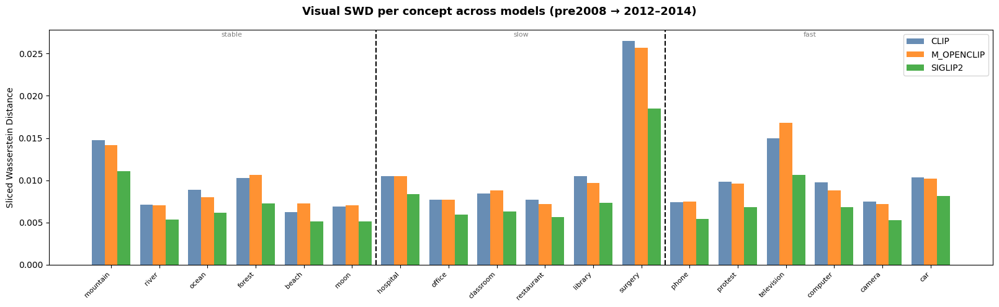

Saved: /content/drive/MyDrive/DL4VSP2Project/results/model_comparison_swd.png


In [ ]:
print(f"MODEL COMPARISON — {' vs '.join(k.upper() for k in CONFIG['models'])}\n")

df_compare = (
    DF_ALL.drop_duplicates(["model", "concept"])
          [["model", "concept", "tier", "vis_swd", "vis_centroid_delta"]]
          .pivot(index="concept", columns="model",
                 values=["vis_swd", "vis_centroid_delta"])
)
df_compare.columns = ["_".join(c) for c in df_compare.columns]
df_compare = df_compare.reset_index()
df_compare["tier"] = df_compare["concept"].map(TIER_MAP)

# ── Pairwise SWD diffs (all model pairs) ──────────────────────────────────
model_keys = list(CONFIG["models"].keys())
pairs = [(a, b) for i, a in enumerate(model_keys)
                for b in model_keys[i+1:]]

print("Visual SWD pairwise differences (positive = row model detects more drift):\n")
for a, b in pairs:
    col_a = f"vis_swd_{a}"
    col_b = f"vis_swd_{b}"
    if col_a in df_compare.columns and col_b in df_compare.columns:
        df_compare[f"diff_{a}_vs_{b}"] = df_compare[col_a] - df_compare[col_b]

display(df_compare.sort_values(f"vis_swd_{model_keys[0]}", ascending=False)
                   .round(6).reset_index(drop=True))

# ── Tier-level mean summary ────────────────────────────────────────────────
print("\nMean vis_swd by tier × model:")
tier_summary = (
    DF_ALL.drop_duplicates(["model", "concept"])
          .groupby(["model", "tier"])["vis_swd"]
          .mean().unstack("model").round(6)
)
display(tier_summary)

# ── Bar chart ─────────────────────────────────────────────────────────────
concept_order = ([c for c in CONFIG["concept_tiers"]["stable"]
                  if c in df_compare["concept"].values] +
                 [c for c in CONFIG["concept_tiers"]["slow"]
                  if c in df_compare["concept"].values] +
                 [c for c in CONFIG["concept_tiers"]["fast"]
                  if c in df_compare["concept"].values])

model_colors = {"clip": "#4e79a7", "openclip": "#f28e2b", "siglip": "#59a14f"}
fig, ax = plt.subplots(figsize=(max(16, len(concept_order) * 0.9), 5))
fig.suptitle("Visual SWD per concept across models (pre2008 → 2012–2014)",
             fontsize=13, fontweight="bold")

n_models = len(model_keys)
width     = 0.8 / n_models
x         = np.arange(len(concept_order))

for i, mk in enumerate(model_keys):
    col = f"vis_swd_{mk}"
    if col not in df_compare.columns: continue
    vals = df_compare.set_index("concept").reindex(concept_order)[col].values
    ax.bar(x + (i - n_models/2 + 0.5) * width, vals, width=width,
           label=mk.upper(), alpha=0.85, color=model_colors.get(mk, f"C{i}"))

ax.set_xticks(x)
ax.set_xticklabels(concept_order, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Sliced Wasserstein Distance")
ax.legend()

# Tier separator lines
n_s = len([c for c in CONFIG["concept_tiers"]["stable"] if c in concept_order])
n_w = len([c for c in CONFIG["concept_tiers"]["slow"]   if c in concept_order])
for sep in [n_s - 0.5, n_s + n_w - 0.5]:
    ax.axvline(sep, color="black", linewidth=1.5, linestyle="--")
ax.text(n_s/2 - 0.5,            ax.get_ylim()[1]*0.97, "stable", ha="center", fontsize=8, color="grey")
ax.text(n_s + n_w/2 - 0.5,      ax.get_ylim()[1]*0.97, "slow",   ha="center", fontsize=8, color="grey")
ax.text(n_s + n_w + (len(concept_order)-n_s-n_w)/2 - 0.5,
        ax.get_ylim()[1]*0.97, "fast", ha="center", fontsize=8, color="grey")

plt.tight_layout()
out = os.path.join(RESULTS_DIR, "model_comparison_swd.png")
plt.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {out}")

## 3.5 Architecture Independence: Intraclass Correlation

The **Intraclass Correlation Coefficient** (ICC) [Shrout and Fleiss, 1979] quantifies how much of a concept's SWD rank is reproducible across vision models (i.e., encoder-independent) versus model-specific.

**Model:** `ICC(A,1)` (two-way random effects, absolute agreement, single rater). Concepts are the subjects; models are the raters; `vis_swd` is the rating. Computed via the `pingouin` library.

Interpretation thresholds (Koo and Li, 2016):
- ICC $> 0.75$: excellent agreement
- $0.50 < $ ICC $\leq 0.75$: moderate agreement
- ICC $\leq 0.50$: poor agreement

INTRACLASS CORRELATION COEFFICIENT

Full ICC table:


,ICC,F,df1,df2,pval,CI95
Type,,,,,,
"ICC(1,1)",0.8330,15.9596,17,36,0.0,"[0.68, 0.93]"
"ICC(A,1)",0.8395,60.7819,17,34,0.0,"[0.31, 0.95]"
"ICC(C,1)",0.9522,60.7819,17,34,0.0,"[0.9, 0.98]"
"ICC(1,k)",0.9373,15.9596,17,36,0.0,"[0.86, 0.97]"
"ICC(A,k)",0.9401,60.7819,17,34,0.0,"[0.57, 0.98]"
"ICC(C,k)",0.9835,60.7819,17,34,0.0,"[0.96, 0.99]"



ICC(2,1) = 0.8395  95% CI [0.3100, 0.9500]  p = 0.0000
Interpretation: EXCELLENT (>0.75): drift rank is largely model-independent.


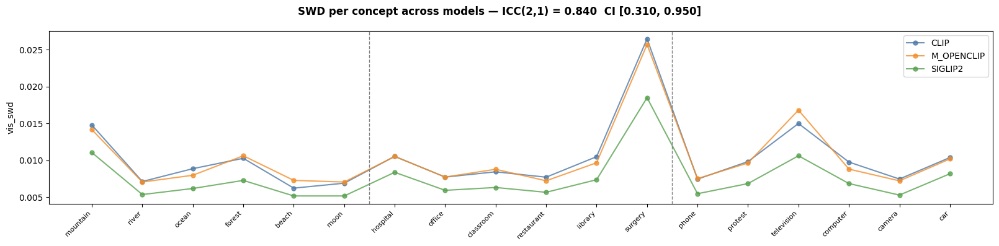

Saved: /content/drive/MyDrive/DL4VSP2Project/results/icc_model_comparison.png
ICC table saved to: icc_results.csv


In [ ]:
print("INTRACLASS CORRELATION COEFFICIENT\n")

# Build long-format table: one row per (concept, model)
df_icc_input = (
    DF_ALL.drop_duplicates(["model", "concept"])
          [["concept", "model", "vis_swd", "tier"]]
          .copy()
)

# pingouin expects: targets (subjects) = concept, raters = model
# ICC(A,1): two-way random effects, absolute agreement, single rater.
# Concepts are subjects; models are raters; vis_swd is the rating.
icc_result = pg.intraclass_corr(
    data    = df_icc_input,
    targets = "concept",
    raters  = "model",
    ratings = "vis_swd",
).set_index("Type")

print("Full ICC table:")
display(icc_result.round(4))

# ICC(2,1) is the standard single-measure, two-way random-effects estimate
icc21 = icc_result.loc["ICC(A,1)", "ICC"]
ci_lo  = icc_result.loc["ICC(A,1)", "CI95"][0]
ci_hi  = icc_result.loc["ICC(A,1)", "CI95"][1]
p_val  = icc_result.loc["ICC(A,1)",  "pval"]

print(f"\nICC(2,1) = {icc21:.4f}  95% CI [{ci_lo:.4f}, {ci_hi:.4f}]  p = {p_val:.4f}")

if icc21 >= 0.75:
    interp = "EXCELLENT (>0.75): drift rank is largely model-independent."
elif icc21 >= 0.50:
    interp = "MODERATE (0.50–0.75): substantial agreement, some encoder-specific variance."
else:
    interp = "POOR (<0.50): drift scores are strongly encoder-dependent."
print(f"Interpretation: {interp}")

# ── Per-concept variance decomposition plot ───────────────────────────────
concept_order_icc = (CONFIG["concept_tiers"]["stable"] +
                     CONFIG["concept_tiers"]["slow"]   +
                     CONFIG["concept_tiers"]["fast"])
concept_order_icc = [c for c in concept_order_icc
                     if c in df_icc_input["concept"].values]

model_colors_icc = {"clip": "#4e79a7", "m_openclip": "#f28e2b", "siglip2": "#59a14f"}

fig, ax = plt.subplots(figsize=(max(14, len(concept_order_icc)*0.9), 4))
fig.suptitle(
    f"SWD per concept across models — ICC(2,1) = {icc21:.3f}  "
    f"CI [{ci_lo:.3f}, {ci_hi:.3f}]",
    fontsize=12, fontweight="bold")

for mk, color in model_colors_icc.items():
    sub = df_icc_input[df_icc_input["model"] == mk].set_index("concept")
    vals = [sub.loc[c, "vis_swd"] if c in sub.index else np.nan
            for c in concept_order_icc]
    ax.plot(range(len(concept_order_icc)), vals, "o-",
            label=mk.upper(), color=color, alpha=0.8, linewidth=1.5, markersize=5)

ax.set_xticks(range(len(concept_order_icc)))
ax.set_xticklabels(concept_order_icc, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("vis_swd")
ax.legend()

n_s = len([c for c in CONFIG["concept_tiers"]["stable"] if c in concept_order_icc])
n_w = len([c for c in CONFIG["concept_tiers"]["slow"]   if c in concept_order_icc])
for sep in [n_s - 0.5, n_s + n_w - 0.5]:
    ax.axvline(sep, color="grey", linestyle="--", linewidth=1)

plt.tight_layout()
out = os.path.join(RESULTS_DIR, "icc_model_comparison.png")
plt.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {out}")

icc_result.round(4).to_csv(os.path.join(RESULTS_DIR, "icc_results.csv"))
print("ICC table saved to: icc_results.csv")

---

# Section IV: Trajectory Analysis

For each concept, the visual centroid trajectory is computed across the three temporal bins. The trajectory angle $\theta_{\text{vis}}$ (Eq. 2 of the paper) is compared against a permutation null obtained by shuffling bin labels 1,000 times and recomputing $\theta$ under each permutation.

A small observed $\theta_{\text{vis}}$ relative to the null median indicates that the concept's embedding evolves along a consistent direction rather than wandering randomly. The Wilcoxon signed-rank test (H3) tests whether observed angles are systematically below their respective null medians across all 18 concepts.

Text trajectory angles $\theta_{\text{text}}$ are also computed per language for exploratory analysis of language-specific directional consistency.

In [ ]:
set_seed(42)
B0, B1, B2 = CONFIG["temporal_bins"]   # pre2008, 2008_2011, 2012_2014

traj_records = []

for concept in CONFIG["concepts"]:
    pools = {b: get_vis(concept, b) for b in CONFIG["temporal_bins"]}
    if any(len(p) < 2 for p in pools.values()):
        continue

    # Visual trajectory
    mu = {b: centroid(pools[b]) for b in CONFIG["temporal_bins"]}
    v1 = mu[B1] - mu[B0]
    v2 = mu[B2] - mu[B1]
    n1, n2 = np.linalg.norm(v1), np.linalg.norm(v2)
    if n1 < 1e-10 or n2 < 1e-10:
        theta_vis = np.nan
    else:
        theta_vis = float(np.degrees(np.arccos(
            np.clip(np.dot(v1 / n1, v2 / n2), -1.0, 1.0)
        )))

    ### Permutation null (shuffle bin labels, recompute θ)
    # Concatenate all images for this concept with their bin labels
    all_embs  = np.vstack([pools[b] for b in CONFIG["temporal_bins"]])
    all_labels = (
        [B0] * len(pools[B0]) +
        [B1] * len(pools[B1]) +
        [B2] * len(pools[B2])
    )
    all_labels = np.array(all_labels)

    # Build permutation null by shuffling bin labels and recomputing theta_vis.
    perm_thetas = []
    for _ in range(CONFIG["n_permutations"]):
        shuffled = all_labels.copy()
        np.random.shuffle(shuffled)
        pm = {b: centroid(all_embs[shuffled == b]) for b in CONFIG["temporal_bins"]}
        pv1 = pm[B1] - pm[B0];  pv2 = pm[B2] - pm[B1]
        pn1, pn2 = np.linalg.norm(pv1), np.linalg.norm(pv2)
        if pn1 > 1e-10 and pn2 > 1e-10:
            perm_thetas.append(float(np.degrees(np.arccos(
                np.clip(np.dot(pv1 / pn1, pv2 / pn2), -1.0, 1.0)
            ))))

    null_median = float(np.median(perm_thetas)) if perm_thetas else np.nan
    null_mean   = float(np.mean(perm_thetas))   if perm_thetas else np.nan

    # Text trajectory (per language)
    for lang in CONFIG["languages"]:
        qt = {b: mean_emb(TEXT_EMBS[lang][concept]["temporal"][b])
              for b in CONFIG["temporal_bins"]}
        tv1 = qt[B1] - qt[B0];  tv2 = qt[B2] - qt[B1]
        tn1, tn2 = np.linalg.norm(tv1), np.linalg.norm(tv2)
        if tn1 < 1e-10 or tn2 < 1e-10:
            theta_text = np.nan
        else:
            theta_text = float(np.degrees(np.arccos(
                np.clip(np.dot(tv1 / tn1, tv2 / tn2), -1.0, 1.0)
            )))

        traj_records.append({
            "concept"     : concept,
            "tier"        : TIER_MAP[concept],
            "language"    : lang,
            "theta_vis"   : theta_vis,      # visual θ (language-independent)
            "theta_text"  : theta_text,     # text θ (language-dependent)
            "null_median" : null_median,
            "null_mean"   : null_mean,
            "delta_theta" : null_median - theta_vis if not np.isnan(theta_vis) else np.nan,
        })

DF_TRAJ = pd.DataFrame(traj_records)

# Save
traj_path = os.path.join(RESULTS_DIR, "trajectory_results.csv")
DF_TRAJ.to_csv(traj_path, index=False)
print(f"Trajectory results saved: {traj_path}\n")

print("Trajectory Results (sorted by more consistent first):\n")
display(
    DF_TRAJ[DF_TRAJ["language"] == "en"]
        [["concept", "tier", "theta_vis", "null_median", "delta_theta", "theta_text"]]
        .sort_values("theta_vis")
        .round(4)
        .reset_index(drop=True)
)

Trajectory results saved: /content/drive/MyDrive/DL4VSP2Project/results/trajectory_results.csv

Trajectory Results (sorted by more consistent first):



,concept,tier,theta_vis,null_median,delta_theta,theta_text
0,hospital,slow,74.9660,119.6348,44.6689,123.2517
1,television,fast,77.5172,119.5482,42.0310,124.2180
2,phone,fast,81.7504,120.0477,38.2973,122.1270
3,surgery,slow,85.8740,120.9784,35.1044,125.1771
4,forest,stable,86.2380,120.3497,34.1117,124.1062
5,camera,fast,86.2876,119.9202,33.6326,123.2435
6,computer,fast,88.5126,120.0573,31.5448,123.0140
7,river,stable,89.0099,120.5616,31.5518,125.7558
8,beach,stable,89.8354,119.5946,29.7592,120.9027
9,restaurant,slow,90.3569,119.8020,29.4450,120.4982


---

# Section V: Statistical Tests

All hypotheses are pre-specified. No post-hoc multiple comparison correction is applied; the pre-specification limits the family-wise error concern to three planned contrasts.

| Hypothesis | Null | Test | Response variable |
|---|---|---|---|
| H1 | Tier does not predict visual drift | LME + permutation test | `ret_swd_k10`, `vis_swd` |
| H2 | Training-data volume does not predict $\delta$ | Spearman $\rho$ + LME | `text_delta` |
| H3 | Trajectories are no more consistent than chance | One-sided Wilcoxon signed-rank | $\theta_{\text{vis}}$ vs permutation null |

## H1: Concept-Tier Drift

**Hypothesis:** Semantic tier (stable / slow / fast) is a significant predictor of visual distributional shift, either directly or in interaction with linguistic resources.

**Primary test:** A **Linear Mixed-Effects Model** [Pinheiro and Bates, 2000] is fitted to `ret_swd_k10` (language-sensitive retrieved SWD) with the following structure:

$$\text{ret_swd_k10}_{ij} = \beta_0 + \beta_1 \text{tier}_i + \beta_2 \log r_j + \beta_3 (\text{tier}_i \times \log r_j) + u_i + \varepsilon_{ij}$$

where $r_j$ is the mC4 resource level of language $j$, $u_i \sim \mathcal{N}(0, \tau^2)$ is a random intercept per concept, and $\varepsilon_{ij}$ is the residual error. Estimation by REML.

**Caveat:** The LME for H1 converges at the boundary of the parameter space (random-intercept variance $\approx 0$), meaning between-concept variance is not identifiable at $n = 18$ concepts. The fixed-effect $p = 0.038$ for the tier-by-resource interaction should therefore be treated as **confirmatory rather than fully inferential**.

In [ ]:
print("H1 — CONCEPT-TIER DRIFT\n")
print("="*60)

# ── Data prep ─────────────────────────────────────────────────────────────
# vis_swd: language-independent (same across all languages for a concept×model)
# ret_swd_k10: language-dependent (text query direction affects retrieved images)

df_h1 = DF[DF["model"] == "clip"].copy() if "model" in DF.columns else DF.copy()

df_vis = df_h1.drop_duplicates("concept")[["concept", "tier", "vis_swd"]].copy()
stable = df_vis[df_vis["tier"] == "stable"]["vis_swd"].values
slow   = df_vis[df_vis["tier"] == "slow"  ]["vis_swd"].values
fast   = df_vis[df_vis["tier"] == "fast"  ]["vis_swd"].values

print(f"Stable vis_swd (n={len(stable)}): mean={stable.mean():.6f}  std={stable.std():.6f}")
print(f"Slow   vis_swd (n={len(slow  )}): mean={slow.mean():.6f}  std={slow.std():.6f}")
print(f"Fast   vis_swd (n={len(fast  )}): mean={fast.mean():.6f}  std={fast.std():.6f}")

# ── UNIFIED MIXED-EFFECTS MODEL ───────────────────────
print("\n--- 1. Unified LME: ret_swd_k10 ~ C(tier) * log_resource + (1|concept) ---")
print("""
DV  : ret_swd_k10  — retrieved-image SWD (language-sensitive; captures both
      visual drift AND text query direction, unifying H1 and H2 into a
      single regression).
FE  : C(tier)         — categorical effect of concept tier (ref = stable)
      log_resource     — continuous language training-data volume
      C(tier):log_resource — interaction: does resource level modulate
                             the tier effect on retrieved drift?
RE  : (1|concept)     — random intercept per concept (accounts for
                         concept-level SWD baseline differences)
""")

try:
    lme_h1 = smf.mixedlm(
        "ret_swd_k10 ~ C(tier, Treatment('stable')) * log_resource",
        df_h1, groups=df_h1["concept"]
    ).fit(reml=True)
    print(lme_h1.summary())

    # Extract key coefficients
    fe   = lme_h1.fe_params
    pval = lme_h1.pvalues
    print("\nKey fixed effects:")
    for param in fe.index:
        sig = "***" if pval[param] < 0.001 else "**" if pval[param] < 0.01 \
              else "*" if pval[param] < 0.05 else "ns"
        print(f"  {param:<45} coef={fe[param]:+.6f}  p={pval[param]:.4f}  {sig}")

    # Tier effect: is fast significantly different from stable?
    fast_terms = [k for k in pval.index if "fast" in k and "log" not in k]
    slow_terms = [k for k in pval.index if "slow" in k and "log" not in k]
    tier_sig   = any(pval[t] < 0.05 for t in fast_terms + slow_terms)
    inter_sig  = any(pval[k] < 0.05 for k in pval.index if ":" in k)

    print(f"\n  Tier main effect significant (fast or slow vs stable): "
          f"{'YES' if tier_sig else 'NO'}")
    print(f"  Tier × log_resource interaction significant: "
          f"{'YES' if inter_sig else 'NO'}")
    print(f"\n  → H1 {'SUPPORTED' if tier_sig else 'NOT SUPPORTED'} by LME "
          f"(α = 0.05)")

except Exception as e:
    print(f"LME error: {e}")

H1 — CONCEPT-TIER DRIFT

Stable vis_swd (n=6): mean=0.009019  std=0.002910
Slow   vis_swd (n=6): mean=0.011889  std=0.006631
Fast   vis_swd (n=6): mean=0.009969  std=0.002523

--- 1. Unified LME: ret_swd_k10 ~ C(tier) * log_resource + (1|concept) ---

DV  : ret_swd_k10  — retrieved-image SWD (language-sensitive; captures both
      visual drift AND text query direction, unifying H1 and H2 into a
      single regression).
FE  : C(tier)         — categorical effect of concept tier (ref = stable)
      log_resource     — continuous language training-data volume
      C(tier):log_resource — interaction: does resource level modulate
                             the tier effect on retrieved drift?
RE  : (1|concept)     — random intercept per concept (accounts for
                         concept-level SWD baseline differences)

                           Mixed Linear Model Regression Results
Model:                         MixedLM            Dependent Variable:            ret_swd_k10
No. Obse

## H1: Supplementary Pairwise Tests

Paired permutation tests (10,000 iterations, sign-flipping) and **Cohen's $d$** effect size are computed for the pairwise contrasts fast vs. stable and fast vs. slow on `vis_swd` (language-independent). These serve as supplementary tests to the LME.

In [ ]:
print("\n--- Pairwise permutation tests (vis_swd, CLIP) ---")

def cohen_d_paired(a, b):
    diff = a - b
    return diff.mean() / (diff.std(ddof=1) + 1e-12)

# Sign-flipping permutation test: under the null, the sign of each paired
# difference is random. One-sided p = fraction of permutations with mean diff >= observed.
def permutation_test_paired(a, b, n_perm=10_000, seed=42):
    rng   = np.random.default_rng(seed)
    obs   = (a - b).mean()
    diffs = a - b
    count = sum((diffs * rng.choice([-1, 1], size=len(diffs))).mean() >= obs
                for _ in range(n_perm))
    return obs, count / n_perm

for label, grp_a, grp_b in [
    ("fast vs stable", fast, stable),
    ("fast vs slow",   fast, slow),
]:
    n = min(len(grp_a), len(grp_b))
    a, b = grp_a[:n], grp_b[:n]
    t_stat, p_two = ttest_rel(a, b)
    p_one = p_two / 2 if t_stat > 0 else 1.0
    obs, p_perm = permutation_test_paired(a, b)
    d = cohen_d_paired(a, b)
    print(f"\n  {label} (n={n} pairs):")
    print(f"    Paired t : t={t_stat:.4f},  p (one-tailed) = {p_one:.4f}")
    print(f"    Permut.  : Δmean={obs:.6f}, p={p_perm:.4f}")
    print(f"    Cohen's d: {d:.4f}  "
          f"({'large' if abs(d)>0.8 else 'medium' if abs(d)>0.5 else 'small'})")

print("\nPer-tier vis_swd summary (CLIP):")
display(df_vis.groupby("tier")["vis_swd"].describe().round(6))


--- Pairwise permutation tests (vis_swd, CLIP) ---

  fast vs stable (n=6 pairs):
    Paired t : t=0.5024,  p (one-tailed) = 0.3184
    Permut.  : Δmean=0.000950, p=0.3191
    Cohen's d: 0.2051  (small)

  fast vs slow (n=6 pairs):
    Paired t : t=-0.5991,  p (one-tailed) = 1.0000
    Permut.  : Δmean=-0.001920, p=0.6735
    Cohen's d: -0.2446  (small)

Per-tier vis_swd summary (CLIP):


,count,mean,std,min,25%,50%,75%,max
tier,,,,,,,,
fast,6.0,0.009969,0.002764,0.007436,0.008026,0.009786,0.010231,0.014990
slow,6.0,0.011889,0.007264,0.007700,0.007893,0.009456,0.010513,0.026484
stable,6.0,0.009019,0.003188,0.006215,0.006942,0.007984,0.009913,0.014779


## H2: Cross-Lingual Asymmetry - Spearman Rank Correlation

**Hypothesis:** Temporal text-direction drift $\delta$ is jointly predicted by language training-data volume and morphological typology.

**Test:** Spearman's rank correlation [Spearman, 1904] between $\log(\text{resource level})$ and $\delta$ across all $n = 108$ (concept, language) pairs (18 concepts $\times$ 6 languages). Spearman's $\rho$ is preferred over Pearson's $r$ because the volume-drift relationship is expected to be monotonic but not necessarily linear, and the log-resource values are order-of-magnitude estimates.

In [ ]:
print("H2 — CROSS-LINGUAL ASYMMETRY")

# n = 18 concepts x 6 languages = 108 (concept, language) observations.
rho, p_rho = spearmanr(DF["log_resource"], DF["text_delta"])
print(f"Spearman ρ = {rho:.4f},  p = {p_rho:.4f}  (n = {len(DF)})")
print(f"  {'H2 SUPPORTED (Spearman)' if p_rho < 0.05 and rho > 0 else 'H2 NOT SUPPORTED (Spearman)'}")

print("\nMean text_delta per language:")
display(DF.groupby("language")[["text_delta", "ret_swd_k10", "ret_swd_k50"]].mean().round(6))

print("\nMean text_delta by tier × language:")
display(DF.groupby(["tier", "language"])["text_delta"].mean().unstack().round(6))

H2 — CROSS-LINGUAL ASYMMETRY
Spearman ρ = 0.6687,  p = 0.0000  (n = 108)
  H2 SUPPORTED (Spearman)

Mean text_delta per language:


,text_delta,ret_swd_k10,ret_swd_k50
language,,,
ar,0.032415,0.020453,0.012855
bn,0.024730,0.019598,0.012413
en,0.032342,0.018067,0.012235
ja,0.055739,0.018803,0.012558
ru,0.050431,0.018886,0.012442
sw,0.015894,0.021719,0.013316



Mean text_delta by tier × language:


language,ar,bn,en,ja,ru,sw
tier,,,,,,
fast,0.033991,0.025927,0.035060,0.056110,0.053747,0.017014
slow,0.029629,0.024460,0.031165,0.054998,0.049846,0.014748
stable,0.033626,0.023802,0.030801,0.056109,0.047702,0.015920


## H2: Cross-Lingual Asymmetry - Linear Mixed-Effects Model

A mixed-effects model regresses $\delta$ on $\log(\text{resource})$ with concept as a random intercept:

$$\delta_{ij} = \beta_0 + \beta_1 \log r_j + u_i + \varepsilon_{ij}$$

This accounts for the non-independence of observations within the same concept (each concept contributes six language measurements).

In [ ]:
try:
    lme_model  = smf.mixedlm("text_delta ~ log_resource",
                              DF, groups=DF["concept"])
    lme_result = lme_model.fit(reml=True)
    print("\nLinear Mixed-Effects Model:")
    print(f"  log_resource coefficient: {lme_result.fe_params['log_resource']:.6f}")
    print(f"  p-value (log_resource)  : {lme_result.pvalues['log_resource']:.4f}")
    print(f"  {'H2 SUPPORTED (LME)' if lme_result.pvalues['log_resource'] < 0.05 else 'H2 NOT SUPPORTED (LME)'}")
    print("\nFull LME summary:")
    print(lme_result.summary())
except Exception as e:
    print(f"LME error: {e}")


Linear Mixed-Effects Model:
  log_resource coefficient: 0.003804
  p-value (log_resource)  : 0.0000
  H2 SUPPORTED (LME)

Full LME summary:
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: text_delta
No. Observations: 108     Method:             REML      
No. Groups:       18      Scale:              0.0001    
Min. group size:  6       Log-Likelihood:     320.4926  
Max. group size:  6       Converged:          Yes       
Mean group size:  6.0                                   
--------------------------------------------------------
              Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------
Intercept     -0.053    0.010 -5.270 0.000 -0.073 -0.033
log_resource   0.004    0.000  8.813 0.000  0.003  0.005
Group Var      0.000                                    



## H2: Joint Regime Classification

Each (concept, language) pair is assigned to a regime using median thresholds on the joint $(\delta, \sigma^2)$ plane:

- **Drifting:** $\delta \geq \delta_{\text{med}}$ and $\sigma^2 \leq \sigma^2_{\text{med}}$ - the text encoder tracks temporal evolution directionally.
- **Frozen:** $\delta < \delta_{\text{med}}$ and $\sigma^2 \leq \sigma^2_{\text{med}}$ - the text encoder produces stable but temporally insensitive queries (Swahili, 17/18 concepts).
- **Noisy:** $\delta < \delta_{\text{med}}$ and $\sigma^2 > \sigma^2_{\text{med}}$ - the text encoder produces diffuse, incoherent embeddings (Bengali, 17/18 concepts).

Note that frozen and noisy are *qualitatively opposite failure modes*: frozen queries are predictably wrong, whereas noisy queries are unpredictably wrong.

In [ ]:
### Joint (Δ, σ²) regime classification
# Δ = text_delta,  σ² = mean of sigma2_pre + sigma2_post
# Mean variance across pre and post bins as the dispersion axis of the regime plot.
DF["text_sigma2_mean"] = (DF["text_sigma2_pre"] + DF["text_sigma2_post"]) / 2
# Median thresholds partition the (delta, sigma2) plane into four regime quadrants.
thresh_delta  = DF["text_delta"].median()
thresh_sigma2 = DF["text_sigma2_mean"].median()

def classify_regime(row):
    d, s = row["text_delta"], row["text_sigma2_mean"]
    if d >= thresh_delta  and s <= thresh_sigma2: return "drifting"
    if d <  thresh_delta  and s <= thresh_sigma2: return "frozen"
    if d <  thresh_delta  and s >  thresh_sigma2: return "noisy"
    return "ambiguous"

DF["regime"] = DF.apply(classify_regime, axis=1)
print("\nRegime classification per language:")
display(DF.groupby(["language", "regime"]).size().unstack(fill_value=0))


Regime classification per language:


regime,ambiguous,drifting,frozen,noisy
language,,,,
ar,9,0,4,5
bn,1,0,0,17
en,8,0,0,10
ja,1,17,0,0
ru,0,18,0,0
sw,0,0,15,3


## H2: Text Direction Drift Bar Chart

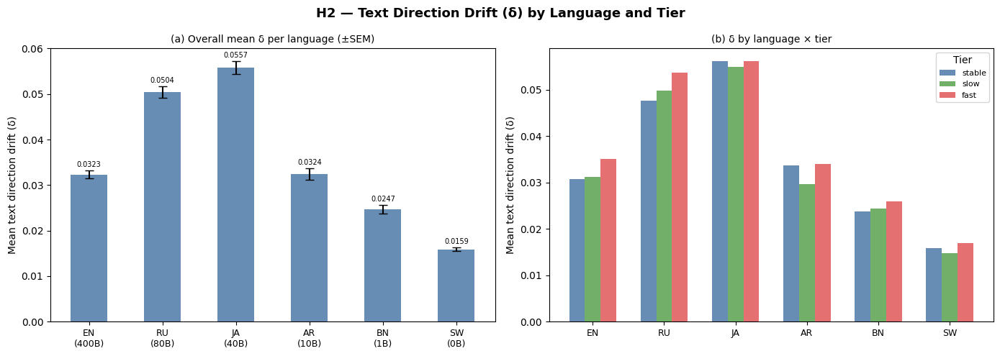

Saved: /content/drive/MyDrive/DL4VSP2Project/results/h2_text_delta_bar.png


In [ ]:
lang_order = sorted(CONFIG["languages"],
                    key=lambda l: CONFIG["resource_level"][l], reverse=True)

tier_colors = {"stable": "#4e79a7", "slow": "#59a14f", "fast": "#e15759"}
tiers       = ["stable", "slow", "fast"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("H2 — Text Direction Drift (δ) by Language and Tier",
             fontsize=13, fontweight="bold")

ax0 = axes[0]
means = [DF[DF["language"] == l]["text_delta"].mean() for l in lang_order]
sems  = [DF[DF["language"] == l]["text_delta"].sem()  for l in lang_order]
x     = np.arange(len(lang_order))
ax0.bar(x, means, yerr=sems, capsize=4, color="#4e79a7", alpha=0.85, width=0.5)
ax0.set_xticks(x)
ax0.set_xticklabels(
    [f"{l.upper()}\n({CONFIG['resource_level'][l]/1e9:.0f}B)" for l in lang_order],
    fontsize=9)
ax0.set_ylabel("Mean text direction drift (δ)")
ax0.set_title("(a) Overall mean δ per language (±SEM)", fontsize=10)

for xi, (m, s) in enumerate(zip(means, sems)):
    ax0.text(xi, m + s + 0.0005, f"{m:.4f}", ha="center", va="bottom", fontsize=7)

ax1 = axes[1]
n_tiers = len(tiers)
bar_w   = 0.22
for j, tier in enumerate(tiers):
    vals = [DF[(DF["language"] == l) & (DF["tier"] == tier)]["text_delta"].mean()
            for l in lang_order]
    ax1.bar(x + (j - 1) * bar_w, vals, width=bar_w,
            label=tier, color=tier_colors[tier], alpha=0.85)

ax1.set_xticks(x)
ax1.set_xticklabels([l.upper() for l in lang_order], fontsize=9)
ax1.set_ylabel("Mean text direction drift (δ)")
ax1.set_title("(b) δ by language × tier", fontsize=10)
ax1.legend(title="Tier", fontsize=8)

plt.tight_layout()
out = os.path.join(RESULTS_DIR, "h2_text_delta_bar.png")
plt.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {out}")

## H3: Trajectory Smoothness - Wilcoxon Signed-Rank Test

**Hypothesis:** Consecutive centroid displacements are directionally more consistent than permutation chance.

**Test:** One-sided Wilcoxon signed-rank test [Wilcoxon, 1945] on the signed differences $\theta_{\text{vis}} - \theta_{\text{null, median}}$ across all 18 concepts, testing whether observed angles are systematically below their respective permutation-null medians.

$W = 0$ occurs when all 18 observed angles fall below their respective null medians, yielding the minimum possible test statistic for the one-sided formulation.

In [ ]:
print("H3 — TRAJECTORY SMOOTHNESS (Wilcoxon signed-rank)")

df_traj_unique = DF_TRAJ.drop_duplicates("concept")[
    ["concept", "tier", "theta_vis", "null_median", "delta_theta"]
].dropna()

observed = df_traj_unique["theta_vis"].values
null_med  = df_traj_unique["null_median"].values
diffs     = observed - null_med

print(f"n concepts with valid trajectory: {len(df_traj_unique)}")
print("\nPer-concept comparison (observed θ vs null median θ):")
display(df_traj_unique.round(4).reset_index(drop=True))

if len(diffs) >= 6:
    # One-sided Wilcoxon: W=0 when ALL 18 observed angles fall below their null medians.
    stat, p_wilcox = wilcoxon(diffs, alternative="less")
    print(f"\nWilcoxon signed-rank test (observed < null, one-sided):")
    print(f"  W = {stat:.4f},  p = {p_wilcox:.4f}")
    print(f"\n  {'H3 SUPPORTED' if p_wilcox < 0.05 else 'H3 NOT SUPPORTED'}"
          f"  (α = 0.05)")
else:
    print(f"\nOnly {len(diffs)} valid observations (Wilcoxon requires ≥6).")
    print("   Reporting descriptive statistics instead:")
    n_consistent = (diffs < 0).sum()
    print(f"   {n_consistent}/{len(diffs)} concepts have observed θ < null median θ")

# Fast-drift concepts specifically
fast_traj = df_traj_unique[df_traj_unique["tier"] == "fast"]
print(f"\nFast-drift concepts only (n={len(fast_traj)}):")
print(f"  Mean observed θ : {fast_traj['theta_vis'].mean():.4f}°")
print(f"  Mean null θ     : {fast_traj['null_median'].mean():.4f}°")
print(f"  Mean Δθ         : {fast_traj['delta_theta'].mean():.4f}° (positive = more consistent than chance)")

H3 — TRAJECTORY SMOOTHNESS (Wilcoxon signed-rank)
n concepts with valid trajectory: 18

Per-concept comparison (observed θ vs null median θ):


,concept,tier,theta_vis,null_median,delta_theta
0,mountain,stable,99.0647,120.4339,21.3691
1,river,stable,89.0099,120.5616,31.5518
2,ocean,stable,107.8392,116.0641,8.2249
3,forest,stable,86.2380,120.3497,34.1117
4,beach,stable,89.8354,119.5946,29.7592
5,moon,stable,102.3098,119.9716,17.6618
6,hospital,slow,74.9660,119.6348,44.6689
7,office,slow,94.7844,118.3345,23.5501
8,classroom,slow,101.4635,122.5695,21.1059
9,restaurant,slow,90.3569,119.8020,29.4450



Wilcoxon signed-rank test (observed < null, one-sided):
  W = 0.0000,  p = 0.0000

  H3 SUPPORTED  (α = 0.05)

Fast-drift concepts only (n=6):
  Mean observed θ : 90.6775°
  Mean null θ     : 120.0474°
  Mean Δθ         : 29.3698° (positive = more consistent than chance)


---

# Section VI: Dataset Artifact Control

Before interpreting SWD values as semantic drift, it is necessary to rule out photographic quality improvements as a confound. Flickr images from 2004 onwards show a systematic increase in sensor resolution and sharpness as digital cameras improved.

**Method:** Laplacian variance [Pech-Pacheco et al., 2000] is computed as a sharpness proxy: for a grayscale image $I$, sharpness $= \mathrm{Var}(\nabla^2 I)$. Higher values indicate sharper images. For each concept, $\Delta\text{sharpness} = \overline{\text{sharpness}}_{\text{post}} - \overline{\text{sharpness}}_{\text{pre}}$ is computed over 50 sampled images per bin.

**Expected null result:** Spearman $\rho(\text{vis\_swd},\ \Delta\text{sharpness})$ should be non-significant if SWD reflects semantic change rather than photographic quality. The artifact control addresses one dimension of photographic style; compositional and colour-grading changes on Flickr during 2004-2014 remain as residual confounds.

DATASET ARTIFACT ANALYSIS — Image Sharpness Shift


Computing sharpness: 100%|██████████| 18/18 [01:11<00:00,  3.96s/it]


Sharpness change vs Visual SWD per concept:


,concept,tier,vis_swd,delta_sharpness
0,surgery,slow,0.0265,202.1438
1,television,fast,0.0150,-72.6149
2,mountain,stable,0.0148,679.6866
3,hospital,slow,0.0105,2132.3486
4,library,slow,0.0105,732.3055
5,car,fast,0.0104,343.2840
6,forest,stable,0.0103,222.1817
7,protest,fast,0.0098,146.6348
8,computer,fast,0.0098,875.7616
9,ocean,stable,0.0089,240.4042



Spearman ρ (vis_swd ~ Δsharpness) = 0.0960,  p = 0.7048
     No strong artifact: SWD drift is not driven by image quality shift.


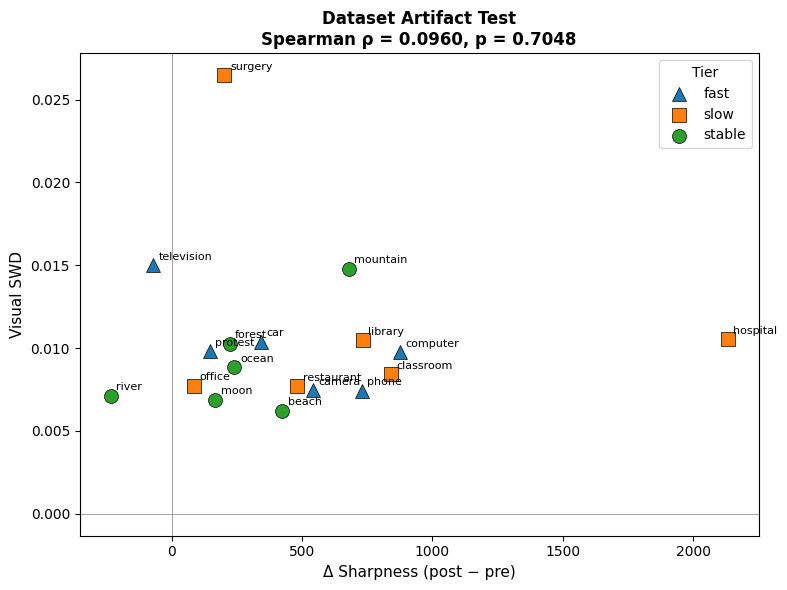

In [ ]:
print("DATASET ARTIFACT ANALYSIS — Image Sharpness Shift")

# Sharpness proxy: variance of the Laplacian of the grayscale image.
# Higher values = sharper edges (Pech-Pacheco et al., 2000).
def laplacian_variance(img_path: str) -> float:
    """Sharpness proxy: variance of Laplacian of grayscale image."""
    try:
        img  = Image.open(img_path).convert("L").resize((128, 128))
        arr  = np.array(img, dtype=np.float32)
        lap  = cv2.Laplacian(arr, cv2.CV_32F)
        return float(lap.var())
    except Exception:
        return np.nan

sharpness_records = []
SAMPLE_PER_BIN = 50   # cap at 50 images per bin per concept for speed

for concept in tqdm(CONFIG["concepts"], desc="Computing sharpness"):
    for t_bin in CONFIG["temporal_bins"]:
        d = os.path.join(IMAGES_DIR, concept, t_bin)
        if not os.path.isdir(d):
            continue
        files = sorted(glob.glob(os.path.join(d, "*.jpg")))[:SAMPLE_PER_BIN]
        scores = [laplacian_variance(f) for f in files]
        scores = [s for s in scores if not np.isnan(s)]
        sharpness_records.append({
            "concept" : concept,
            "tier"    : TIER_MAP[concept],
            "t_bin"   : t_bin,
            "mean_sharpness": np.mean(scores) if scores else np.nan,
            "n"       : len(scores),
        })

df_sharp = pd.DataFrame(sharpness_records)

# Compute Δsharpness = post − pre per concept
df_pre  = df_sharp[df_sharp["t_bin"] == "pre2008" ].set_index("concept")["mean_sharpness"]
df_post = df_sharp[df_sharp["t_bin"] == "2012_2014"].set_index("concept")["mean_sharpness"]
df_delta_sharp = (df_post - df_pre).rename("delta_sharpness").reset_index()

# Merge with vis_swd
df_artifact = df_vis[["concept", "tier", "vis_swd"]].merge(df_delta_sharp, on="concept")
print("\nSharpness change vs Visual SWD per concept:")
display(df_artifact.sort_values("vis_swd", ascending=False).round(4).reset_index(drop=True))

# Spearman test
rho_art, p_art = spearmanr(df_artifact["vis_swd"], df_artifact["delta_sharpness"])
print(f"\nSpearman ρ (vis_swd ~ Δsharpness) = {rho_art:.4f},  p = {p_art:.4f}")
if rho_art > 0.5 and p_art < 0.05:
    print("     ARTIFACT DETECTED: SWD significantly correlates with sharpness shift.")
elif rho_art < 0.3:
    print("     No strong artifact: SWD drift is not driven by image quality shift.")
else:
    print("     orderline: mixed signal. See scatter below.")

# Scatter plot
fig, ax = plt.subplots(figsize=(8, 6))
for tier, sub in df_artifact.groupby("tier"):
    m = {"stable": "o", "slow": "s", "fast": "^"}[tier]
    ax.scatter(sub["delta_sharpness"], sub["vis_swd"],
               label=tier, s=100, marker=m, edgecolors="black", linewidths=0.5)
    for _, row in sub.iterrows():
        ax.annotate(row["concept"], (row["delta_sharpness"], row["vis_swd"]),
                    fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Δ Sharpness (post − pre)", fontsize=11)
ax.set_ylabel("Visual SWD", fontsize=11)
ax.set_title(f"Dataset Artifact Test\nSpearman ρ = {rho_art:.4f}, p = {p_art:.4f}",
             fontsize=12, fontweight="bold")
ax.legend(title="Tier")
ax.axhline(0, color="grey", linewidth=0.5)
ax.axvline(0, color="grey", linewidth=0.5)

plt.tight_layout()
plt.show()

---

# Section VII: Retrieval Quality

**MAP@k** [Manning et al., 2008] is computed as a sanity check and a measure of the practical consequence of the H2 regime gradient. Neutral prompts (without temporal anchors) are used so that retrieval quality reflects the semantic resolution of the text encoder for each language.

**Setup:**
- Pool: all 19,334 images (all concepts and bins mixed).
- Query: mean neutral text embedding $\bar{\mathbf{q}}_{c,\ell}$ for concept $c$ in language $\ell$.
- Relevant: any image where `matched_concept == c` (bin-agnostic).
- Metrics: Precision@10, Precision@50, MAP@10, MAP@50.

**Each model uses its own aligned text encoder** for retrieval (M-CLIP for CLIP, XLM-RoBERTa for M-OpenCLIP, SigLIP-2 encoder for SigLIP-2), so MAP@k measures the joint quality of visual and text alignment for each model-language pair.

Table V of the paper (MAP@10) directly quantifies the practical consequence of the H2 regime gradient: languages classified as frozen or noisy suffer the largest retrieval degradation.

## 7.1 Average Precision at k

In [ ]:
# Average Precision at k: area under the precision-recall curve truncated at k.
def average_precision_at_k(relevance, k):
    relevance = relevance[:k].astype(float)
    if relevance.sum() == 0:
        return 0.0
    hits, running_sum = 0, 0.0
    for i, r in enumerate(relevance):
        if r:
            hits += 1
            running_sum += hits / (i + 1)
    return running_sum / min(k, relevance.sum())


retrieval_records = []

print("Retrieval Quality Evaluation\n")
print("Each model uses its own aligned text encoder:")
print("  CLIP      -> M-CLIP (fine-tuned on CLIP, 512-dim)")
print("  M-OpenCLIP -> XLM-RoBERTa tokenizer (native, 512-dim)")
print("  SigLIP-2   -> SigLIP-2 text encoder (native, 768-dim)\n")

for model_key, model_cfg in CONFIG["models"].items():
    _embs = VIS_EMBS[model_key]
    _meta = DF_META[model_key]
    emb_src = TEXT_EMB_MAP[model_key]

    for lang in CONFIG["languages"]:
        for concept in tqdm(CONFIG["concepts"],
                            desc=f"Retrieval [{model_key}|{lang}]"):
            q = mean_emb(emb_src[lang][concept]["neutral"])
            sims       = _embs @ q
            sorted_idx = np.argsort(sims)[::-1]
            relevance  = (_meta.loc[sorted_idx, "concept"].values == concept).astype(int)

            for k in CONFIG["k_values"]:
                retrieval_records.append({
                    "model"    : model_key,
                    "concept"  : concept,
                    "tier"     : TIER_MAP[concept],
                    "language" : lang,
                    "k"        : k,
                    "precision": relevance[:k].mean(),
                    "AP"       : average_precision_at_k(relevance, k),
                })

DF_RETRIEVAL = pd.DataFrame(retrieval_records)
retrieval_path = os.path.join(RESULTS_DIR, "retrieval_quality.csv")
DF_RETRIEVAL.to_csv(retrieval_path, index=False)
print(f"\nRetrieval quality saved: {retrieval_path}")

Retrieval Quality Evaluation

Each model uses its own aligned text encoder:
  CLIP      -> M-CLIP (fine-tuned on CLIP, 512-dim)
  M-OpenCLIP -> XLM-RoBERTa tokenizer (native, 512-dim)
  SigLIP-2   -> SigLIP-2 text encoder (native, 768-dim)



Retrieval [clip|en]: 100%|██████████| 18/18 [00:00<00:00, 167.49it/s]
Retrieval [clip|ru]: 100%|██████████| 18/18 [00:00<00:00, 177.36it/s]
Retrieval [clip|ja]: 100%|██████████| 18/18 [00:00<00:00, 136.15it/s]
Retrieval [clip|ar]: 100%|██████████| 18/18 [00:00<00:00, 177.86it/s]
Retrieval [clip|bn]: 100%|██████████| 18/18 [00:00<00:00, 179.37it/s]
Retrieval [clip|sw]: 100%|██████████| 18/18 [00:00<00:00, 152.96it/s]
Retrieval [m_openclip|en]: 100%|██████████| 18/18 [00:00<00:00, 173.03it/s]
Retrieval [m_openclip|ru]: 100%|██████████| 18/18 [00:00<00:00, 173.47it/s]
Retrieval [m_openclip|ja]: 100%|██████████| 18/18 [00:00<00:00, 133.33it/s]
Retrieval [m_openclip|ar]: 100%|██████████| 18/18 [00:00<00:00, 174.42it/s]
Retrieval [m_openclip|bn]: 100%|██████████| 18/18 [00:00<00:00, 174.43it/s]
Retrieval [m_openclip|sw]: 100%|██████████| 18/18 [00:00<00:00, 152.14it/s]
Retrieval [siglip2|en]: 100%|██████████| 18/18 [00:00<00:00, 113.98it/s]
Retrieval [siglip2|ru]: 100%|██████████| 18/18 [00:


Retrieval quality saved: /content/drive/MyDrive/DL4VSP2Project/results/retrieval_quality.csv


## 7.2 MAP@k Summary and Bar Chart

Retrieval Quality Summary

-- CLIP --


mean_P@k   MAP@k
language k                   
ar       10    0.7778  0.8694
         50    0.7433  0.7966
bn       10    0.1556  0.1909
         50    0.1400  0.1924
en       10    0.8611  0.9093
         50    0.7789  0.8543
ja       10    0.8167  0.8901
         50    0.7644  0.8169
ru       10    0.7611  0.8537
         50    0.6989  0.7677
sw       10    0.2500  0.2893
         50    0.2122  0.2553


-- M_OPENCLIP --


mean_P@k   MAP@k
language k                   
ar       10    0.8167  0.8863
         50    0.7656  0.8144
bn       10    0.5611  0.6586
         50    0.5089  0.5809
en       10    0.8333  0.8755
         50    0.7822  0.8250
ja       10    0.7944  0.8797
         50    0.7189  0.7874
ru       10    0.8778  0.9037
         50    0.7656  0.8304
sw       10    0.2389  0.3259
         50    0.2167  0.2708


-- SIGLIP2 --


mean_P@k   MAP@k
language k                   
ar       10    0.6667  0.7249
         50    0.6578  0.6974
bn       10    0.5778  0.6898
         50    0.5067  0.5960
en       10    0.8556  0.8813
         50    0.7789  0.8356
ja       10    0.5611  0.6469
         50    0.5067  0.5594
ru       10    0.7611  0.8338
         50    0.7344  0.7716
sw       10    0.2222  0.3142
         50    0.2244  0.2608


-- Cross-model MAP@10 (all languages, mean across concepts) --


,overall_MAP@10,en,ru,ja,ar,bn,sw
model,,,,,,,
CLIP,0.6671,0.9093,0.8537,0.8901,0.8694,0.1909,0.2893
M_OPENCLIP,0.7550,0.8755,0.9037,0.8797,0.8863,0.6586,0.3259
SIGLIP2,0.6818,0.8813,0.8338,0.6469,0.7249,0.6898,0.3142



Saved: /content/drive/MyDrive/DL4VSP2Project/results/retrieval_summary.csv


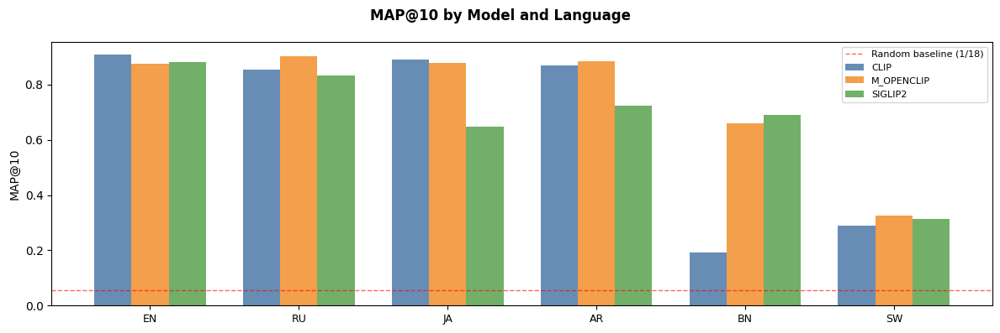

Saved: /content/drive/MyDrive/DL4VSP2Project/results/retrieval_map10_bar.png


In [ ]:
print("Retrieval Quality Summary\n" + "=" * 60)

lang_order = sorted(CONFIG["languages"],
                    key=lambda l: CONFIG["resource_level"][l], reverse=True)

for mk in CONFIG["models"]:
    sub = DF_RETRIEVAL[DF_RETRIEVAL["model"] == mk]
    if sub.empty: continue
    print(f"\n-- {mk.upper()} --")
    map_summary = (
        sub.groupby(["language", "k"])[["precision", "AP"]]
           .mean()
           .rename(columns={"precision": "mean_P@k", "AP": "MAP@k"})
           .round(4)
    )
    display(map_summary)

print("\n-- Cross-model MAP@10 (all languages, mean across concepts) --")
cross = []
for mk in CONFIG["models"]:
    sub = DF_RETRIEVAL[(DF_RETRIEVAL["model"] == mk) & (DF_RETRIEVAL["k"] == 10)]
    if sub.empty: continue
    row = {"model": mk.upper(), "overall_MAP@10": round(sub["AP"].mean(), 4)}
    for lang in lang_order:
        row[lang] = round(sub[sub["language"] == lang]["AP"].mean(), 4)
    cross.append(row)
df_cross = pd.DataFrame(cross).set_index("model")
display(df_cross)

out = os.path.join(RESULTS_DIR, "retrieval_summary.csv")
df_cross.to_csv(out)
print(f"\nSaved: {out}")

fig, ax = plt.subplots(figsize=(12, 4))
fig.suptitle("MAP@10 by Model and Language", fontsize=12, fontweight="bold")
model_colors = {"CLIP": "#4e79a7", "M_OPENCLIP": "#f28e2b", "SIGLIP2": "#59a14f"}
n_models = len(CONFIG["models"])
bar_w    = 0.25
x        = np.arange(len(lang_order))
for j, mk in enumerate(CONFIG["models"]):
    sub = DF_RETRIEVAL[(DF_RETRIEVAL["model"] == mk) & (DF_RETRIEVAL["k"] == 10)]
    vals = [sub[sub["language"] == l]["AP"].mean() for l in lang_order]
    ax.bar(x + (j - n_models/2 + 0.5) * bar_w, vals, width=bar_w,
           label=mk.upper(), color=model_colors.get(mk.upper(), f"C{j}"), alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels([l.upper() for l in lang_order], fontsize=9)
ax.set_ylabel("MAP@10")
ax.axhline(1/len(CONFIG["concepts"]), color="red", linestyle="--",
           linewidth=1, alpha=0.6, label=f"Random baseline (1/{len(CONFIG['concepts'])})")
ax.legend(fontsize=8)
plt.tight_layout()
out = os.path.join(RESULTS_DIR, "retrieval_map10_bar.png")
plt.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {out}")

---

# Section VIII: Visualizations

## 8.1 UMAP Projection of Visual Embedding Spaces

UMAP [McInnes et al., 2018] projects each model's visual embedding matrix from $d$ dimensions to 2D for qualitative inspection. Parameters: `n_neighbors=30`, `min_dist=0.1`, `metric='cosine'`, `random_state=42`.

Points are coloured by temporal bin. Strong temporal mixing across all three tiers is expected under H1 not being supported; local clustering would be consistent with H3.

Fitting UMAP on clip embeddings (19296 images)...
UMAP done. Shape: (19296, 2)


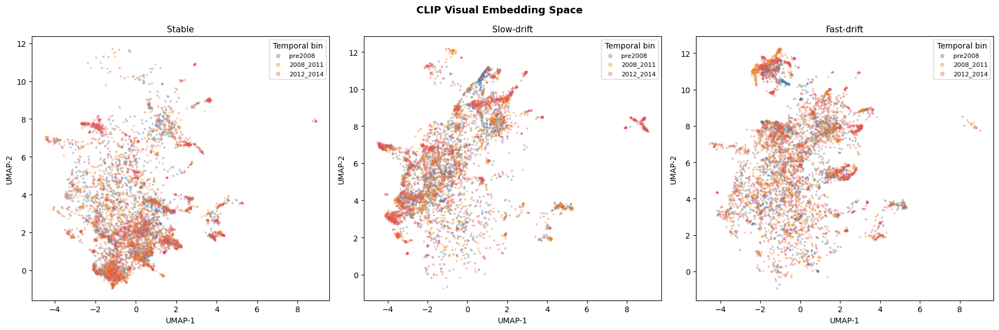

Saved: /content/drive/MyDrive/DL4VSP2Project/results/umap_clip.png

Fitting UMAP on m_openclip embeddings (19296 images)...
UMAP done. Shape: (19296, 2)


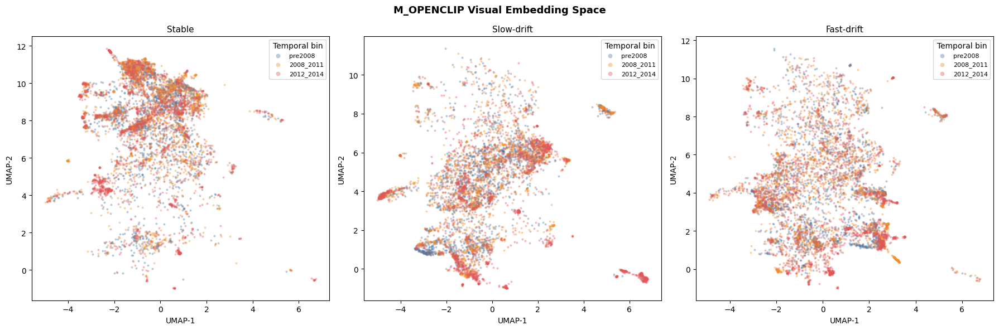

Saved: /content/drive/MyDrive/DL4VSP2Project/results/umap_m_openclip.png

Fitting UMAP on siglip2 embeddings (19296 images)...
UMAP done. Shape: (19296, 2)


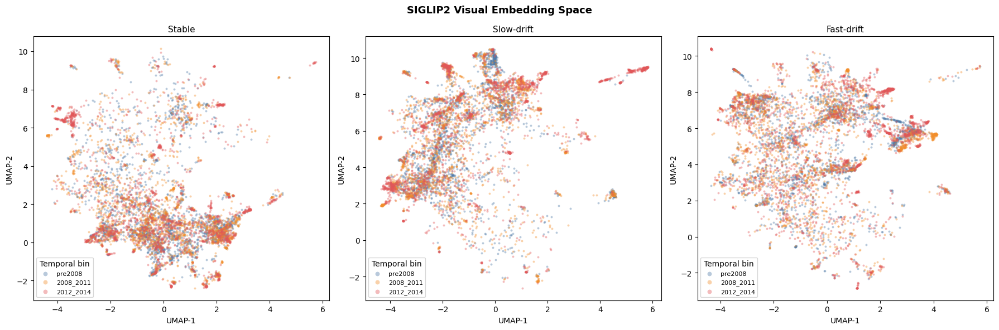

Saved: /content/drive/MyDrive/DL4VSP2Project/results/umap_siglip2.png



In [ ]:
set_seed(42)

for model_key in CONFIG["models"]:
    _embs = VIS_EMBS[model_key]
    _meta = DF_META[model_key]

    print(f"Fitting UMAP on {model_key} embeddings ({_embs.shape[0]} images)...")
    reducer = umap_lib.UMAP(
        n_components=2, n_neighbors=30, min_dist=0.1,
        metric="cosine", random_state=42, low_memory=False,
    )
    umap_2d = reducer.fit_transform(_embs)
    np.save(os.path.join(RESULTS_DIR, f"umap_2d_{model_key}.npy"), umap_2d)
    print(f"UMAP done. Shape: {umap_2d.shape}")

    tier_palette = {"pre2008": "#4e79a7", "2008_2011": "#f28e2b",
                    "2012_2014": "#e15759"}
    tiers      = ["stable", "slow", "fast"]
    tier_titles = {"stable": "Stable", "slow": "Slow-drift", "fast": "Fast-drift"}

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle(
        f"{model_key.upper()} Visual Embedding Space",
        fontsize=13, fontweight="bold")

    for ax, tier in zip(axes, tiers):
        mask     = _meta["concept"].isin(CONFIG["concept_tiers"][tier])
        sub_embs = umap_2d[mask]
        sub_bins = _meta.loc[mask, "temp_bin"].values
        for t_bin, colour in tier_palette.items():
            m2 = sub_bins == t_bin
            ax.scatter(sub_embs[m2, 0], sub_embs[m2, 1],
                       c=colour, label=t_bin, alpha=0.4, s=8, linewidths=0)
        ax.set_title(tier_titles[tier], fontsize=11)
        ax.set_xlabel("UMAP-1"); ax.set_ylabel("UMAP-2")
        ax.legend(title="Temporal bin", fontsize=8, markerscale=2)

    plt.tight_layout()
    out = os.path.join(RESULTS_DIR, f"umap_{model_key}.png")
    plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {out}\n")

## 8.2 Anomaly Spotlight

Quantitative summaries for the two novel phenomena identified in the paper.

**Semantic fossilization** (television, English): the English text encoder becomes anchored to the dominant visual archetype of the training corpus (CRT television sets). Temporal anchors in prompts produce insufficient directional shift to overcome this anchor. The quantitative fingerprint is the inverted EN/BN retrieved-image SWD ratio: English queries retrieve *less* temporally diverse imagery than Bengali queries despite a resource advantage of more than two orders of magnitude.

**Medical modernization anomaly** (surgery): surgery (labeled slow-drift) produces the highest visual SWD of all 18 concepts (0.0265), exceeding television (0.0150) by 77%. This reflects a paradigm shift in YFCC15M surgical imagery from a uniform archetype of operating-room teams (pre-2008) to post-operative patient experience documentation (2012-2014), driven by the proliferation of laparoscopic platforms, digital intraoperative imaging, and social-media patient documentation during 2004-2014.

In [ ]:
print("ANOMALY SPOTLIGHT")

print("\n[1] PROTEST — Near-Random Trajectory")
protest_row = DF_TRAJ[DF_TRAJ["concept"] == "protest"].iloc[0]
phone_dt    = DF_TRAJ[DF_TRAJ["concept"] == "phone"]["delta_theta"].values[0]
print(f"    Observed theta : {protest_row['theta_vis']:.2f} deg")
print(f"    Null median    : {protest_row['null_median']:.2f} deg")
print(f"    Delta-theta    : {protest_row['delta_theta']:.2f} deg  (vs phone: {phone_dt:.2f} deg)")

print("\n[2] TELEVISION — Semantic Fossilization")
tv_vis   = DF[DF["concept"] == "television"]["vis_swd"].iloc[0]
tv_en    = DF[(DF["concept"] == "television") & (DF["language"] == "en")]["text_delta"].iloc[0]
tv_bn    = DF[(DF["concept"] == "television") & (DF["language"] == "bn")]["text_delta"].iloc[0]
phone_en = DF[(DF["concept"] == "phone")      & (DF["language"] == "en")]["text_delta"].iloc[0]
print(f"    Television vis_swd   : {tv_vis:.6f}")
print(f"    Television EN text d : {tv_en:.6f}")
print(f"    Television BN text d : {tv_bn:.6f}")
print(f"    Phone      EN text d : {phone_en:.6f}  (for comparison)")

print("\n[3] Retrieved-image SWD ratio (EN / BN) for fast-drift concepts at k=10:")
print("    ratio < 1 -> EN retrieves LESS diverse imagery (Fossilization)")
for concept in CONFIG["concept_tiers"]["fast"]:
    if concept not in DF["concept"].values: continue
    en_v = DF[(DF["concept"] == concept) & (DF["language"] == "en")]["ret_swd_k10"].values
    bn_v = DF[(DF["concept"] == concept) & (DF["language"] == "bn")]["ret_swd_k10"].values
    if len(en_v) == 0 or len(bn_v) == 0: continue
    ratio = en_v[0] / bn_v[0] if bn_v[0] > 0 else float("nan")
    flag  = " <- fossilized" if ratio < 0.95 else ""
    print(f"  {concept:<14} EN={en_v[0]:.5f}  BN={bn_v[0]:.5f}  ratio={ratio:.2f}x{flag}")

print("\n[4] SURGERY — Slow-Drift Concept with Fast-Drift Visual Signal")
surg_swd  = DF[DF["concept"] == "surgery"]["vis_swd"].iloc[0]
surg_traj = DF_TRAJ[DF_TRAJ["concept"] == "surgery"]
tv_swd    = DF[DF["concept"] == "television"]["vis_swd"].iloc[0]
print(f"    surgery vis_swd    : {surg_swd:.6f}  (highest of all 18 concepts)")
print(f"    television vis_swd : {tv_swd:.6f}  (second highest)")
if len(surg_traj):
    print(f"    theta_vis          : {surg_traj.iloc[0]['theta_vis']:.2f} deg   "
          f"delta_theta = {surg_traj.iloc[0]['delta_theta']:.2f} deg")
print("    Surgery changed more visually than any technology concept 2004-2014:")
print("    laparoscopic proliferation, robotic surgery (da Vinci), digital OR")
print("    imaging, and sterile draping standards all shifted the visual space")
print("    substantially. This challenges the slow-drift classification and")
print("    suggests procedure-type concepts warrant their own tier.")

ANOMALY SPOTLIGHT

[1] PROTEST — Near-Random Trajectory
    Observed theta : 118.25 deg
    Null median    : 120.44 deg
    Delta-theta    : 2.19 deg  (vs phone: 38.30 deg)

[2] TELEVISION — Semantic Fossilization
    Television vis_swd   : 0.014990
    Television EN text d : 0.028014
    Television BN text d : 0.022664
    Phone      EN text d : 0.035218  (for comparison)

[3] Retrieved-image SWD ratio (EN / BN) for fast-drift concepts at k=10:
    ratio < 1 -> EN retrieves LESS diverse imagery (Fossilization)
  phone          EN=0.01996  BN=0.01635  ratio=1.22x
  protest        EN=0.02021  BN=0.02016  ratio=1.00x
  television     EN=0.02181  BN=0.02392  ratio=0.91x <- fossilized
  computer       EN=0.01729  BN=0.01883  ratio=0.92x <- fossilized
  camera         EN=0.02151  BN=0.01803  ratio=1.19x
  car            EN=0.01897  BN=0.01881  ratio=1.01x

[4] SURGERY — Slow-Drift Concept with Fast-Drift Visual Signal
    surgery vis_swd    : 0.026484  (highest of all 18 concepts)
    telev

## 8.3 Drift Heatmap

Two-panel heatmap visualising the full drift profile:

- **Left panel:** visual SWD per concept (language-independent). Concepts are ordered by semantic tier; tier boundaries are marked with black horizontal lines.
- **Right panel:** text direction drift $\delta$ per (concept, language) cell, with languages ordered from high to low mC4 resource volume (left to right).

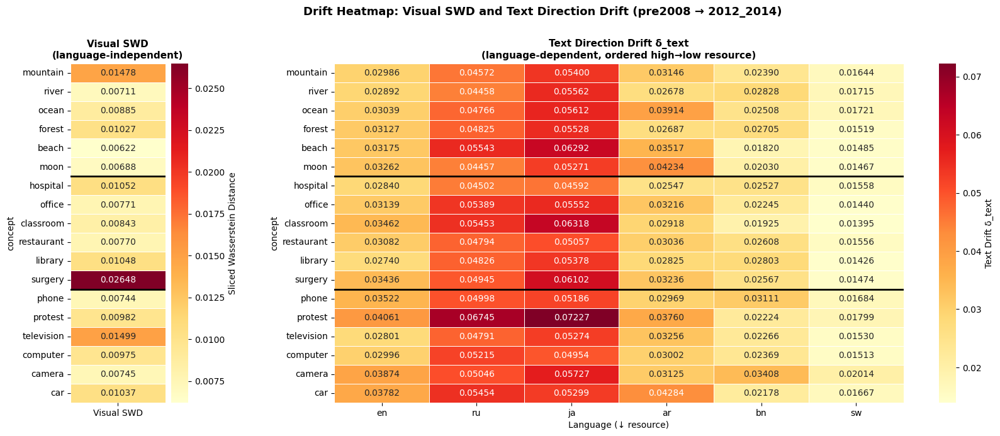

Saved: drift_heatmap.png


In [ ]:
fig = plt.figure(figsize=(20, 7))
gs  = gridspec.GridSpec(1, 2, width_ratios=[1, len(CONFIG["languages"])],
                        wspace=0.35)

concept_order = (CONFIG["concept_tiers"]["stable"] +
                 CONFIG["concept_tiers"]["slow"]   +
                 CONFIG["concept_tiers"]["fast"])
# Only keep concepts that exist in DF (in case running with original 10)
concept_order = [c for c in concept_order if c in DF["concept"].unique()]

# ── Left panel: Visual SWD (language-independent) ─────────────
ax_vis = fig.add_subplot(gs[0])
vis_vals = (DF.drop_duplicates("concept")
              .set_index("concept")["vis_swd"]
              .reindex(concept_order))
sns.heatmap(
    pd.DataFrame(vis_vals.values, index=vis_vals.index, columns=["Visual SWD"]),
    ax=ax_vis, annot=True, fmt=".5f", cmap="YlOrRd",
    linewidths=0.5, cbar_kws={"label": "Sliced Wasserstein Distance"}
)
ax_vis.set_title("Visual SWD\n(language-independent)", fontsize=11, fontweight="bold")
ax_vis.set_xlabel("")
# Tier separator lines
n_stable = len([c for c in concept_order if TIER_MAP.get(c) == "stable"])
n_slow   = len([c for c in concept_order if TIER_MAP.get(c) == "slow"])
for sep in [n_stable, n_stable + n_slow]:
    ax_vis.axhline(sep, color="black", linewidth=2)

# ── Right panel: Text direction drift Δ (language-dependent) ──
ax_txt = fig.add_subplot(gs[1])
pivot = DF.pivot(index="concept", columns="language", values="text_delta")
pivot = pivot.reindex(concept_order)
# Reorder columns by resource level (high → low)
lang_order = sorted(CONFIG["languages"],
                    key=lambda l: CONFIG["resource_level"][l], reverse=True)
pivot = pivot[[l for l in lang_order if l in pivot.columns]]
sns.heatmap(
    pivot, ax=ax_txt, annot=True, fmt=".5f", cmap="YlOrRd",
    linewidths=0.5, cbar_kws={"label": "Text Drift δ_text"}
)
ax_txt.set_title("Text Direction Drift δ_text\n(language-dependent, ordered high→low resource)",
                 fontsize=11, fontweight="bold")
ax_txt.set_xlabel("Language (↓ resource)")
for sep in [n_stable, n_stable + n_slow]:
    ax_txt.axhline(sep, color="black", linewidth=2)

fig.suptitle("Drift Heatmap: Visual SWD and Text Direction Drift (pre2008 → 2012_2014)",
             fontsize=13, fontweight="bold", y=1.01)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "drift_heatmap.png"),
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: drift_heatmap.png")

## 8.4 Visual Centroid Trajectory Plot

PCA-projected (2D) centroid trajectories for each concept under each vision model. A global PCA fit on the full embedding matrix is used to preserve cross-concept geometry. Red trajectories: fast-drift concepts. Blue: stable concepts.

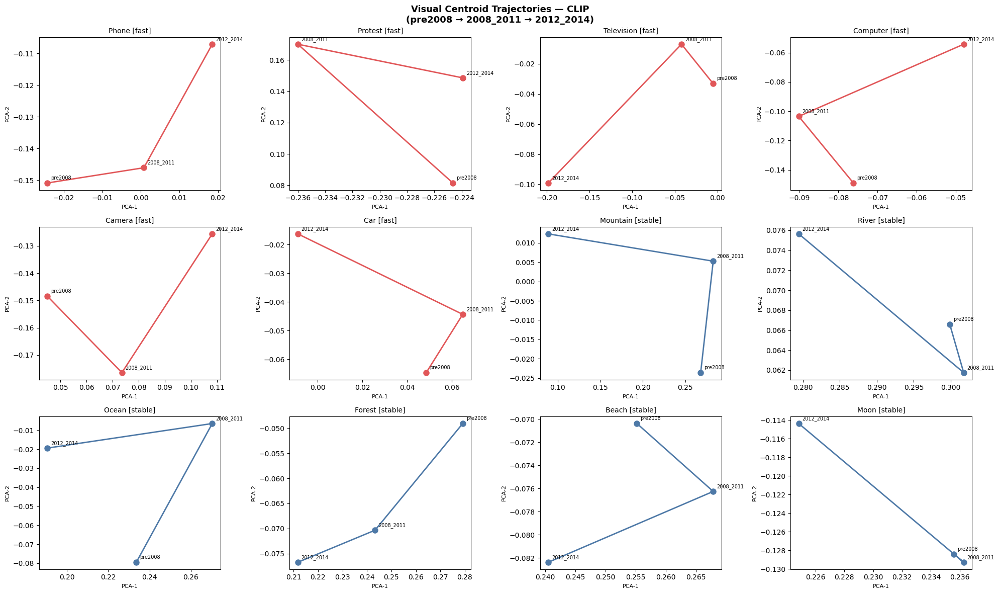

Saved: /content/drive/MyDrive/DL4VSP2Project/results/visual_centroid_trajectory_clip.png



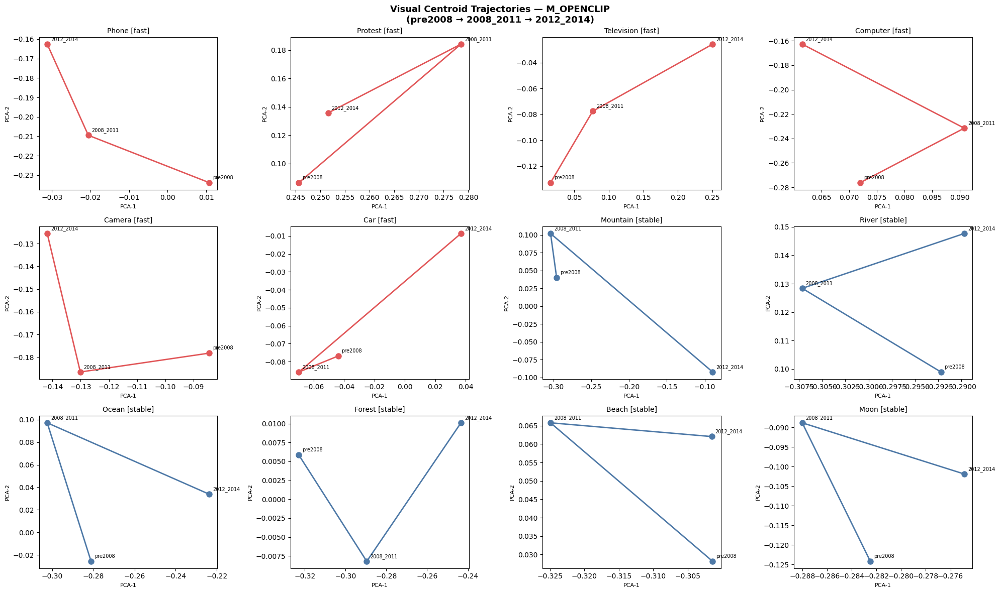

Saved: /content/drive/MyDrive/DL4VSP2Project/results/visual_centroid_trajectory_m_openclip.png



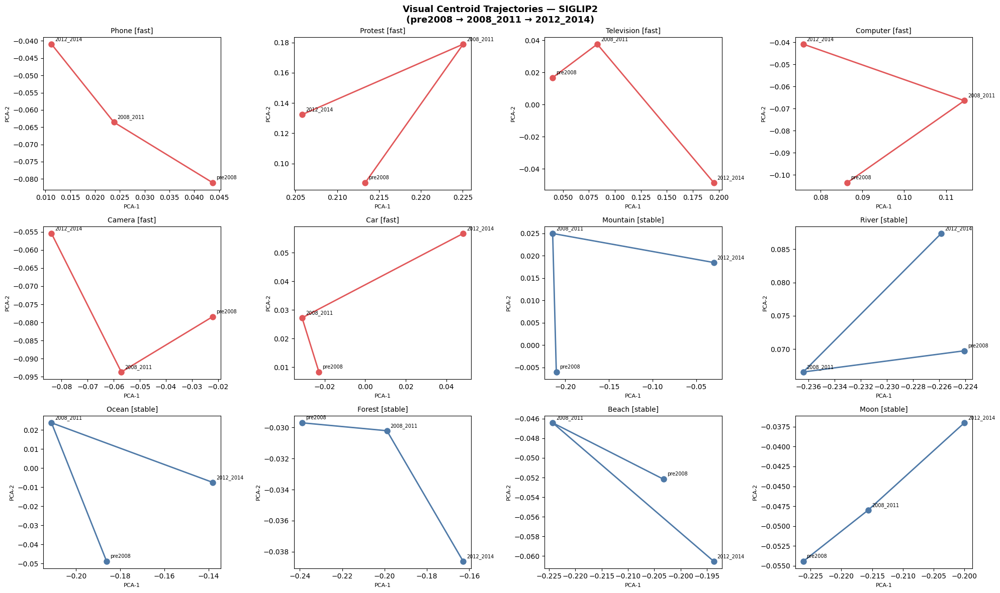

Saved: /content/drive/MyDrive/DL4VSP2Project/results/visual_centroid_trajectory_siglip2.png



In [ ]:
set_seed(42)
B0, B1, B2 = CONFIG["temporal_bins"]
concepts_to_plot = (CONFIG["concept_tiers"]["fast"] +
                    CONFIG["concept_tiers"]["stable"])
n_plots = len(concepts_to_plot)
ncols   = 4
nrows   = (n_plots + ncols - 1) // ncols

for model_key in CONFIG["models"]:
    _embs_pca = VIS_EMBS[model_key]

    pca = PCA(n_components=2, random_state=42)
    pca.fit(_embs_pca)

    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(5 * ncols, 4 * nrows))
    axes = axes.flatten()
    fig.suptitle(
        f"Visual Centroid Trajectories — {model_key.upper()}\n"
        f"(pre2008 → 2008_2011 → 2012_2014)",
        fontsize=13, fontweight="bold")

    tier_color = {"stable": "#4e79a7", "slow": "#59a14f", "fast": "#e15759"}

    for ax, concept in zip(axes, concepts_to_plot):
        centroids_3d = np.array([
            centroid(get_vis(concept, b, model_key))
            for b in CONFIG["temporal_bins"]
        ])
        pts_2d = pca.transform(centroids_3d)
        color  = tier_color[TIER_MAP[concept]]
        ax.plot(pts_2d[:, 0], pts_2d[:, 1], "-o",
                color=color, linewidth=2, markersize=8, zorder=3)
        for label, pt in zip([B0, B1, B2], pts_2d):
            ax.annotate(label, pt, fontsize=7, ha="left",
                        xytext=(5, 5), textcoords="offset points")
        ax.set_title(f"{concept.capitalize()} [{TIER_MAP[concept]}]",
                     fontsize=10)
        ax.set_xlabel("PCA-1", fontsize=8)
        ax.set_ylabel("PCA-2", fontsize=8)

    for ax in axes[n_plots:]:
        ax.set_visible(False)

    plt.tight_layout()
    out = os.path.join(RESULTS_DIR,
                       f"visual_centroid_trajectory_{model_key}.png")
    plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {out}\n")

## 8.5 H2 Regime Classification Scatter

One scatter plot per language in the joint $(\Delta, \sigma^2)$ plane. Dashed lines mark the median thresholds used for regime classification. Points are coloured by regime and shaped by concept tier. Languages are ordered by mC4 resource volume from high (top-left) to low (bottom-right).

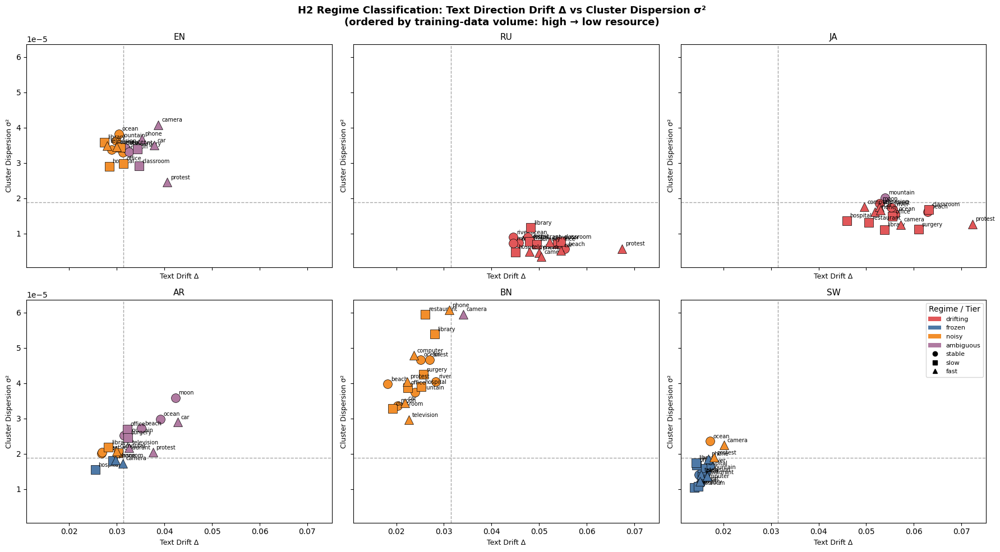

Saved: h2_regime_scatter.png


In [ ]:
n_langs = len(CONFIG["languages"])
ncols   = min(n_langs, 3)
nrows   = (n_langs + ncols - 1) // ncols
fig, axes_arr = plt.subplots(nrows, ncols,
                              figsize=(6 * ncols, 5 * nrows),
                              sharey=True, sharex=True)
axes_flat = np.array(axes_arr).flatten()

fig.suptitle("H2 Regime Classification: Text Direction Drift Δ vs Cluster Dispersion σ²\n"
             "(ordered by training-data volume: high → low resource)",
             fontsize=13, fontweight="bold")

regime_colors = {
    "drifting" : "#e15759",
    "frozen"   : "#4e79a7",
    "noisy"    : "#f28e2b",
    "ambiguous": "#b07aa1",
}
tier_markers = {"stable": "o", "slow": "s", "fast": "^"}

# Order languages by resource level descending
lang_order = sorted(CONFIG["languages"],
                    key=lambda l: CONFIG["resource_level"][l], reverse=True)

for ax, lang in zip(axes_flat, lang_order):
    sub = DF[DF["language"] == lang].copy()
    for _, row in sub.iterrows():
        m = tier_markers[row["tier"]]
        c = regime_colors[row["regime"]]
        ax.scatter(row["text_delta"], row["text_sigma2_mean"],
                   marker=m, color=c, s=130, zorder=3,
                   edgecolors="black", linewidths=0.5)
        ax.annotate(row["concept"], (row["text_delta"], row["text_sigma2_mean"]),
                    fontsize=7, xytext=(4, 4), textcoords="offset points")
    ax.axvline(thresh_delta,  color="grey", linestyle="--", linewidth=1, alpha=0.7)
    ax.axhline(thresh_sigma2, color="grey", linestyle="--", linewidth=1, alpha=0.7)
    ax.set_title(f"{lang.upper()}", fontsize=11)
    ax.set_xlabel("Text Drift Δ", fontsize=9)
    ax.set_ylabel("Cluster Dispersion σ²", fontsize=9)

# Hide unused subplots
for ax in axes_flat[n_langs:]:
    ax.set_visible(False)

# Unified legend
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
legend_elements = (
    [Patch(facecolor=c, label=r) for r, c in regime_colors.items()] +
    [Line2D([0], [0], marker=m, color="k", linestyle="None", label=t)
     for t, m in tier_markers.items()]
)
axes_flat[n_langs - 1].legend(handles=legend_elements, fontsize=8,
                               loc="upper right", title="Regime / Tier")

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "h2_regime_scatter.png"),
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: h2_regime_scatter.png")

---

# Section IX: Qualitative Retrieval Grids

Top-5 retrieval grids for curated (concept, language, model) triples that directly ground each major quantitative finding in the paper:

| Grid | Purpose |
|---|---|
| television, EN, CLIP | Semantic fossilization: EN archetype lock |
| television, BN, CLIP | Fossilization contrast: BN diffuse retrieval |
| phone, EN, CLIP | Technology evolution: CLIP / M-CLIP |
| phone, JA, CLIP | Morphological discontinuity: JA lexical substitution *denwa* to *sumatofon* |
| protest, EN, CLIP | Near-random trajectory anomaly |
| car, EN, CLIP | Fast-drift validation: automotive design |
| surgery, EN, CLIP | Medical modernization anomaly |
| mountain, EN, CLIP | Stable baseline and photographic style confound |
| television, EN, SigLIP-2 | Architecture-independent fossilization check |
| phone, EN, SigLIP-2 | Technology evolution under SigLIP-2 |

Note: Top-K image retrieval grids require the image files to be present on Google Drive. Outputs are not included in the cached notebook to keep file size manageable.

Generating curated paper-quality retrieval grids...

CONCEPT         LANG      MODEL  RATIONALE
----------------------------------------------------------------------
  television      en       clip  Semantic Fossilization — EN archetype lock
  television      bn       clip  Fossilization contrast — BN no archetype
  phone           en       clip  Technology evolution — CLIP/M-CLIP
  phone           ja       clip  Morphological discontinuity — JA lexical jump
  protest         en       clip  Anomaly — near-random trajectory
  car             en       clip  Fast-drift validation — automotive design
  surgery         en       clip  Slow-drift validation — OR modernisation
  mountain        en       clip  Stable baseline + photographic artifact
  television      en    siglip2  Fossilization — SigLIP cross-architecture check
  phone           en    siglip2  Technology evolution — SigLIP


── TELEVISION | EN | CLIP ──
   Semantic Fossilization — EN archetype lock


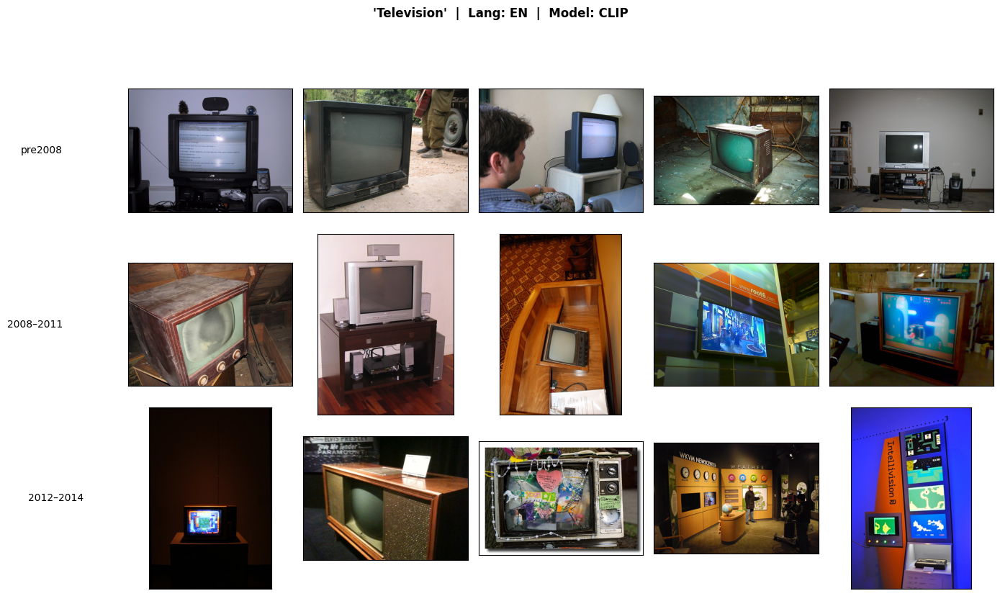

Saved: /content/drive/MyDrive/DL4VSP2Project/results/grid_television_en_clip.png

── TELEVISION | BN | CLIP ──
   Fossilization contrast — BN no archetype


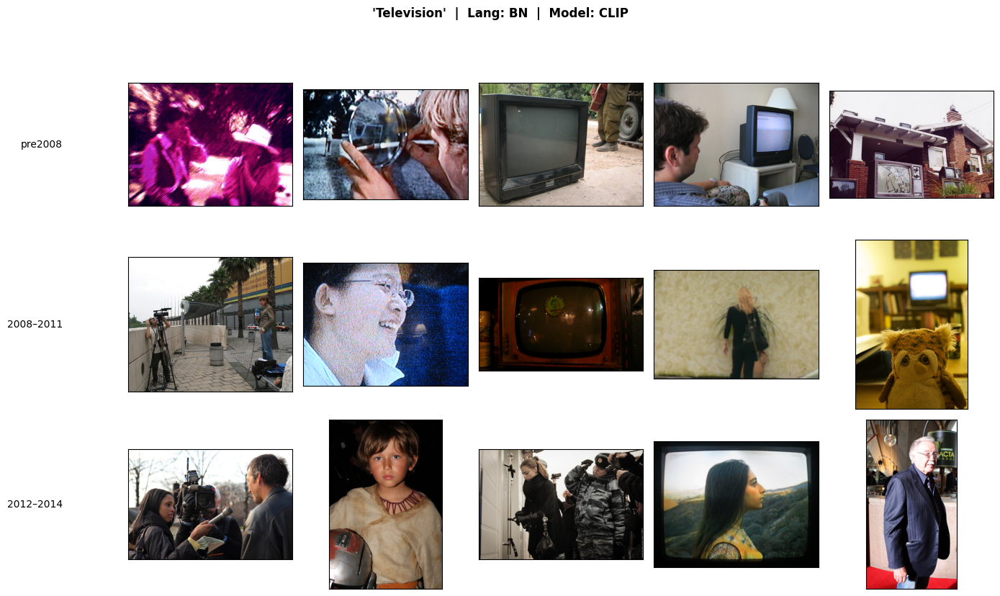

Saved: /content/drive/MyDrive/DL4VSP2Project/results/grid_television_bn_clip.png

── PHONE | EN | CLIP ──
   Technology evolution — CLIP/M-CLIP


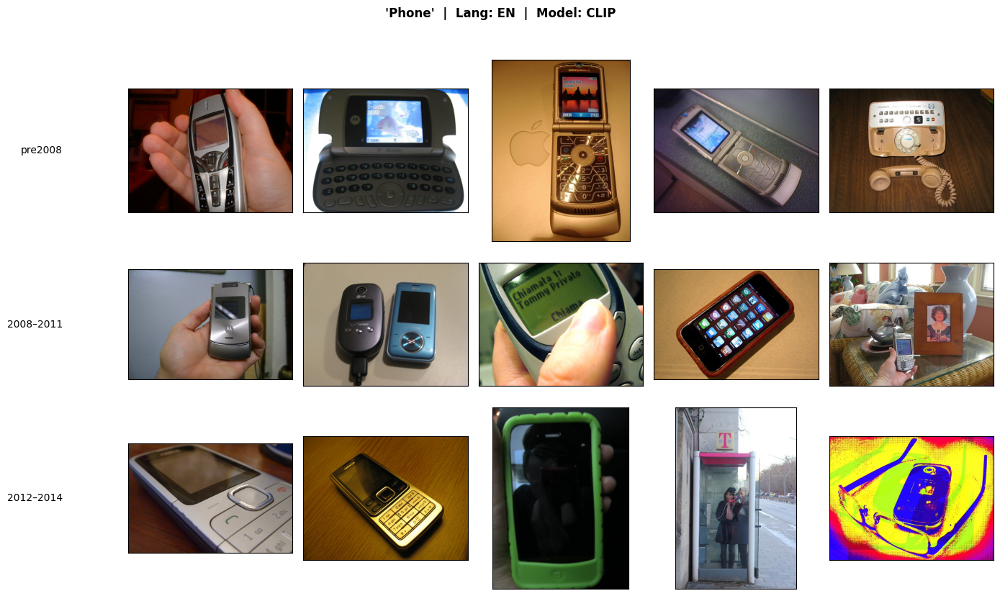

Saved: /content/drive/MyDrive/DL4VSP2Project/results/grid_phone_en_clip.png

── PHONE | JA | CLIP ──
   Morphological discontinuity — JA lexical jump


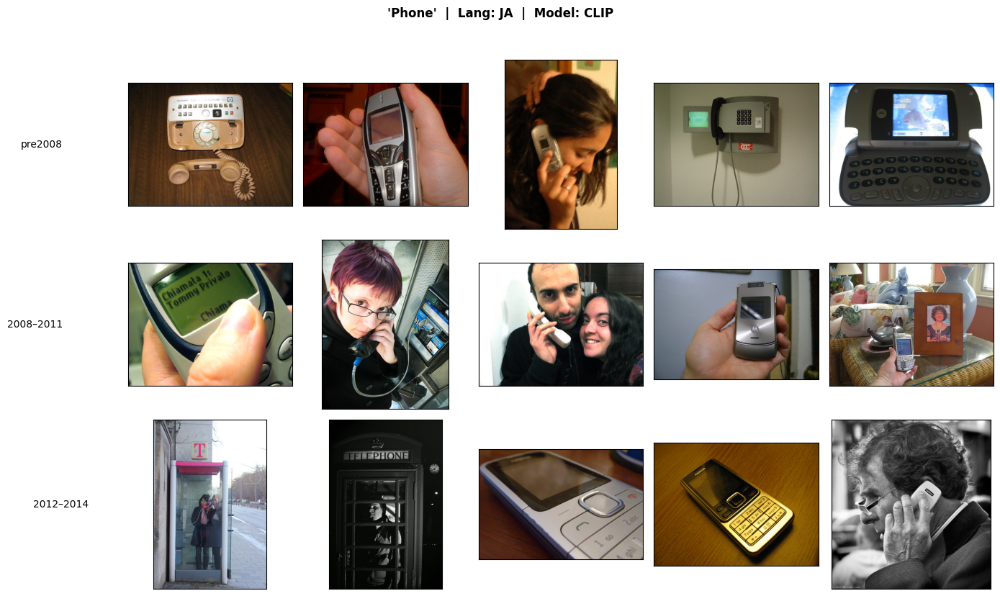

Saved: /content/drive/MyDrive/DL4VSP2Project/results/grid_phone_ja_clip.png

── PROTEST | EN | CLIP ──
   Anomaly — near-random trajectory


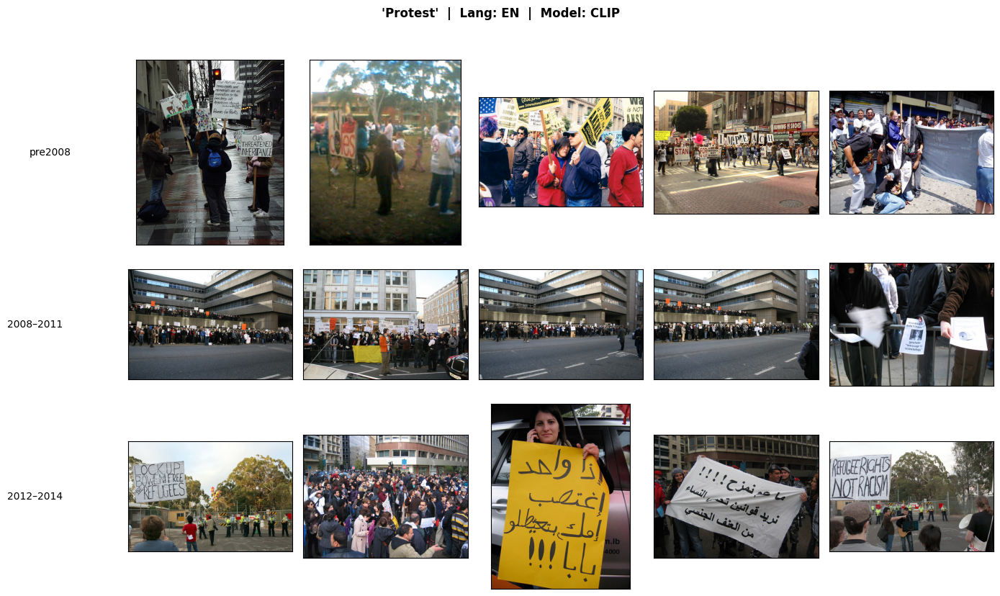

Saved: /content/drive/MyDrive/DL4VSP2Project/results/grid_protest_en_clip.png

── CAR | EN | CLIP ──
   Fast-drift validation — automotive design


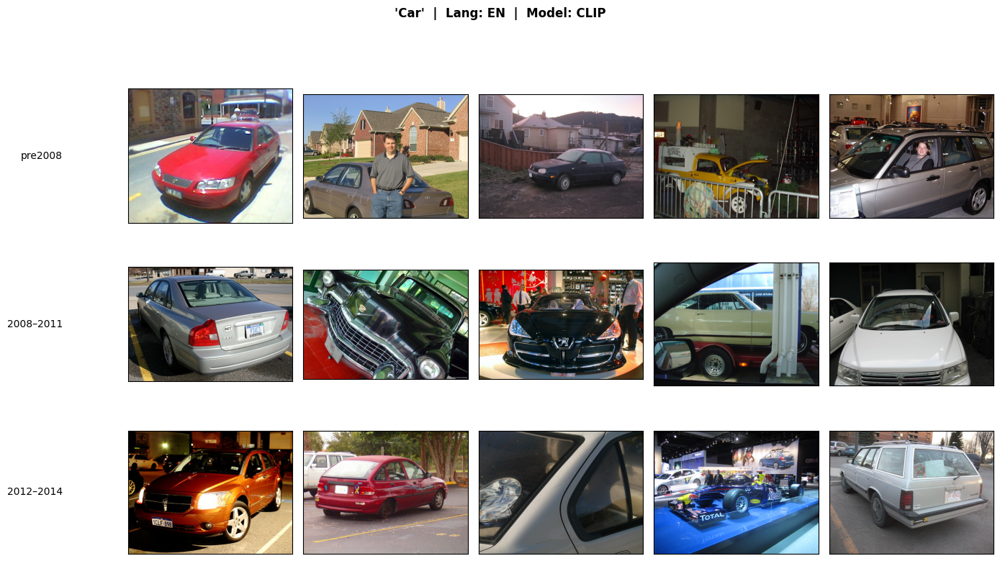

Saved: /content/drive/MyDrive/DL4VSP2Project/results/grid_car_en_clip.png

── SURGERY | EN | CLIP ──
   Slow-drift validation — OR modernisation


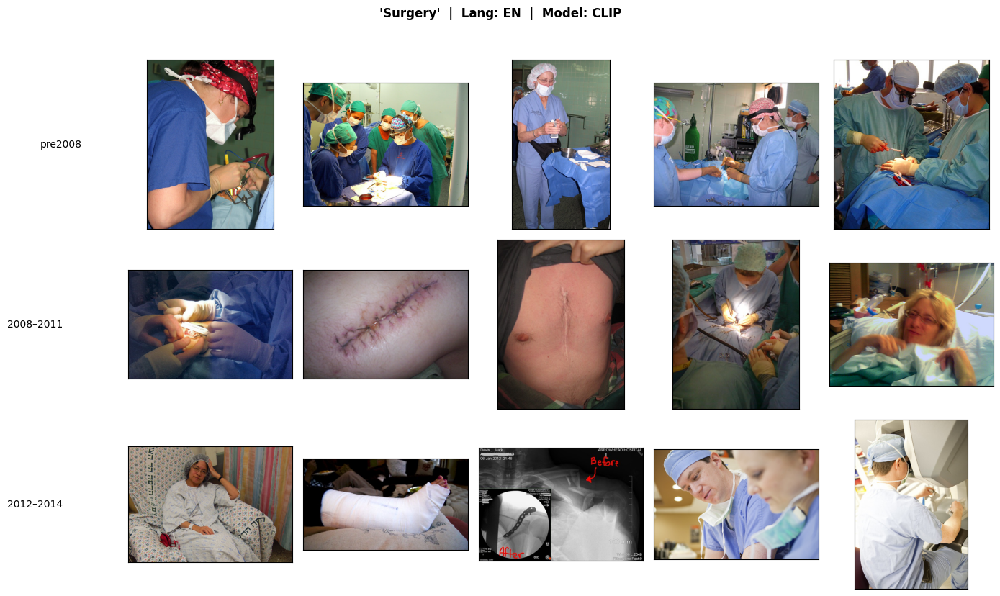

Saved: /content/drive/MyDrive/DL4VSP2Project/results/grid_surgery_en_clip.png

── MOUNTAIN | EN | CLIP ──
   Stable baseline + photographic artifact


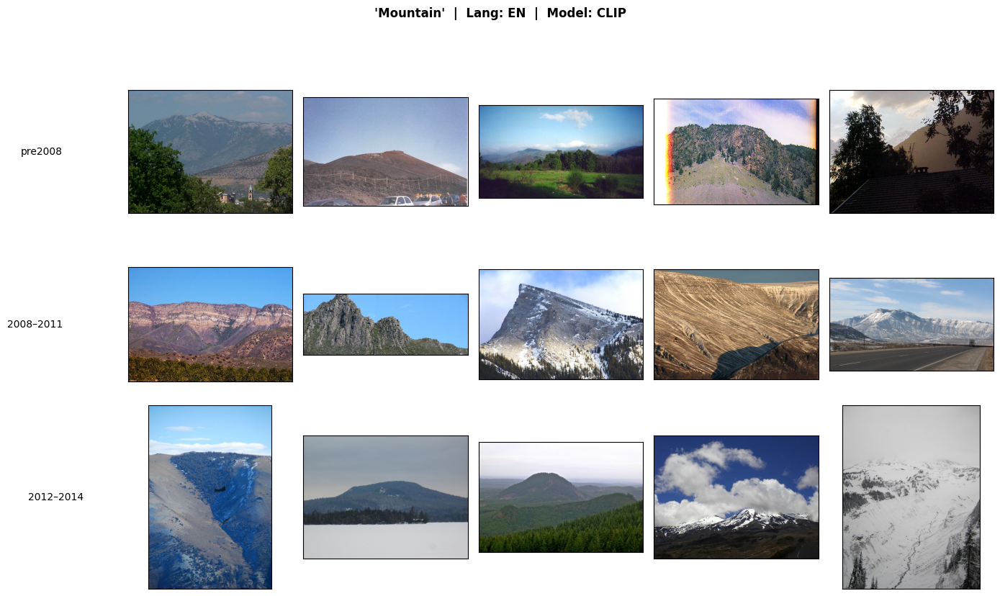

Saved: /content/drive/MyDrive/DL4VSP2Project/results/grid_mountain_en_clip.png

── TELEVISION | EN | SIGLIP2 ──
   Fossilization — SigLIP cross-architecture check


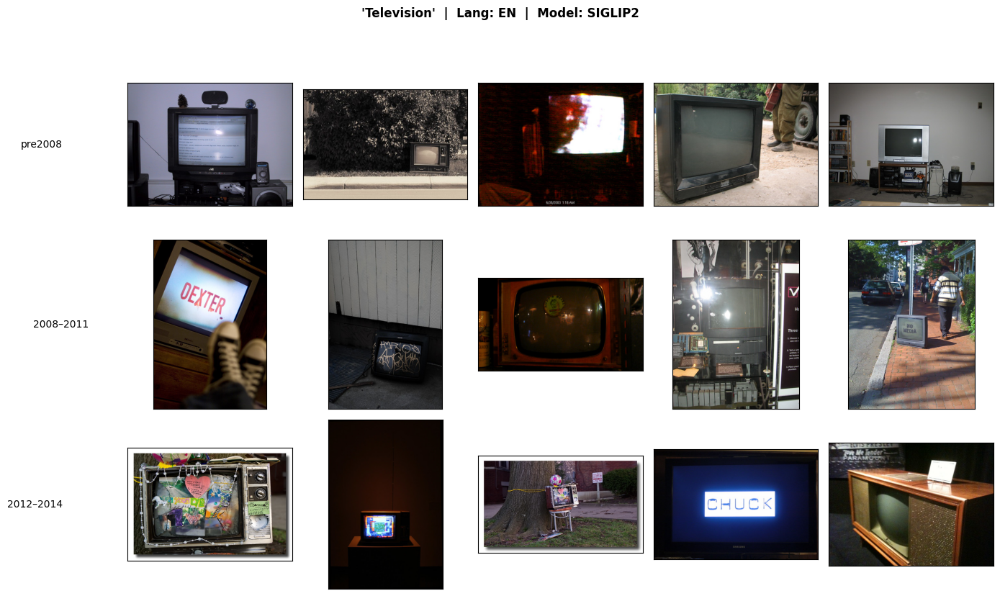

Saved: /content/drive/MyDrive/DL4VSP2Project/results/grid_television_en_siglip2.png

── PHONE | EN | SIGLIP2 ──
   Technology evolution — SigLIP


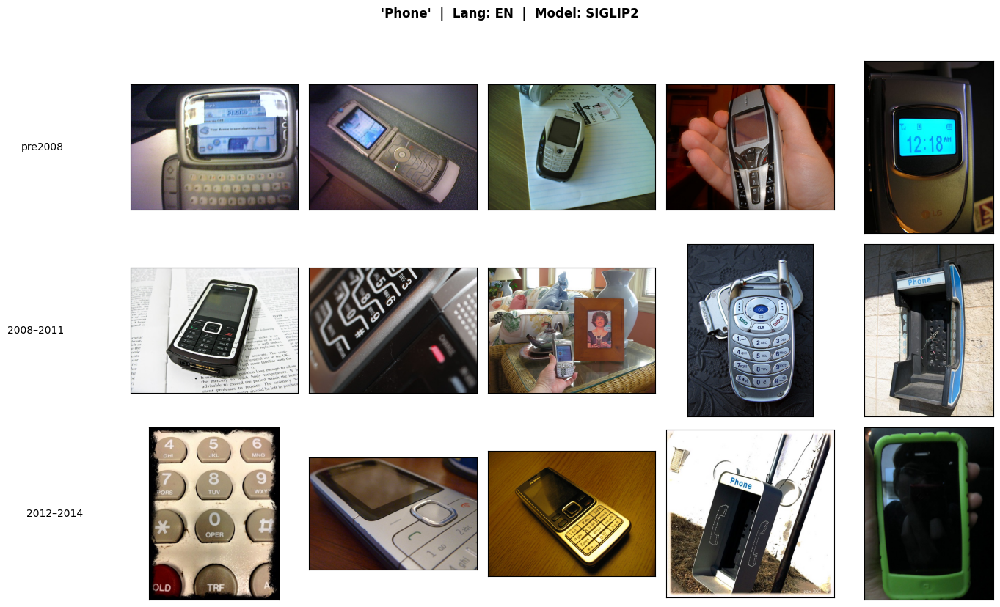

Saved: /content/drive/MyDrive/DL4VSP2Project/results/grid_phone_en_siglip2.png


In [ ]:
def build_retrieval_grid(concept: str, lang: str, k: int = 5,
                         model: str = None):
    """
    Retrieves top-k images per temporal bin using each model's own
    aligned text encoder.
    """
    m     = model or ACTIVE_MODEL
    _meta = DF_META[m]
    _embs = VIS_EMBS[m]

    # Route text source based on model
    # Use the appropriate embedding dictionary based on the model type
    if m == "siglip2":
        emb_src = SIGLIP2_TEXT_EMBS
    elif m == "m_openclip":
        emb_src = MOC_TEXT_EMBS
    else:
        emb_src = TEXT_EMBS

    bins = CONFIG["temporal_bins"]
    fig, axes = plt.subplots(len(bins), k, figsize=(k * 2.8, len(bins) * 2.8))
    fig.suptitle(
        f"'{concept.capitalize()}'  |  Lang: {lang.upper()}  |  "
        f"Model: {m.upper()}",
        fontsize=12, fontweight="bold"
    )

    for row_idx, t_bin in enumerate(bins):
        # Correctly access nested dict: [lang][concept]["temporal"][t_bin]
        raw = emb_src[lang][concept]["temporal"][t_bin]
        q = raw.mean(axis=0)
        q = q / np.linalg.norm(q)   # L2-normalise mean embedding

        # Index into model-specific pool
        pool_mask = ((_meta["concept"] == concept) &
                     (_meta["temp_bin"]  == t_bin))
        pool_idx  = _meta[pool_mask].index.tolist()

        if not pool_idx:
            for col_idx in range(k):
                ax = axes[row_idx, col_idx]
                ax.text(0.5, 0.5, "no images", ha="center", va="center",
                        transform=ax.transAxes, fontsize=8, color="grey")
                ax.set_xticks([]); ax.set_yticks([])
            axes[row_idx, 0].set_ylabel(
                t_bin.replace("_", "–"), fontsize=10,
                rotation=0, labelpad=65, ha="right", va="center")
            continue

        pool_embs = _embs[pool_idx]          # (N, D) — D matches q
        sims      = pool_embs @ q            # (N,)
        top_local = np.argsort(sims)[-k:][::-1]
        filenames = _meta.loc[
            [pool_idx[i] for i in top_local], "filename"
        ].tolist()

        axes[row_idx, 0].set_ylabel(
            t_bin.replace("_", "–"), fontsize=10,
            rotation=0, labelpad=65, ha="right", va="center")

        for col_idx, fname in enumerate(filenames):
            ax       = axes[row_idx, col_idx]
            img_path = os.path.join(IMAGES_DIR, concept, t_bin, fname)
            try:
                img = Image.open(img_path).convert("RGB")
                ax.imshow(img)
            except FileNotFoundError:
                ax.text(0.5, 0.5, "missing", ha="center", va="center",
                        transform=ax.transAxes, fontsize=8, color="red")
            ax.set_xticks([]); ax.set_yticks([])

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    out = os.path.join(RESULTS_DIR, f"grid_{concept}_{lang}_{m}.png")
    plt.savefig(out, dpi=130, bbox_inches="tight")
    plt.show()
    print(f"Saved: {out}")


# ── Curated paper-quality grids ────────────────────────────────────────────

PAPER_GRIDS = [
    # (concept,      lang,  model,      rationale)
    ("television",  "en",  "clip",     "Semantic Fossilization — EN archetype lock"),
    ("television",  "bn",  "clip",     "Fossilization contrast — BN no archetype"),
    ("phone",       "en",  "clip",     "Technology evolution — CLIP/M-CLIP"),
    ("phone",       "ja",  "clip",     "Morphological discontinuity — JA lexical jump"),
    ("protest",     "en",  "clip",     "Anomaly — near-random trajectory"),
    ("car",         "en",  "clip",     "Fast-drift validation — automotive design"),
    ("surgery",     "en",  "clip",     "Slow-drift validation — OR modernisation"),
    ("mountain",    "en",  "clip",     "Stable baseline + photographic artifact"),
    ("television",  "en",  "siglip2",  "Fossilization — SigLIP cross-architecture check"),
    ("phone",       "en",  "siglip2",  "Technology evolution — SigLIP"),
]

print("Generating curated paper-quality retrieval grids...\n")
print(f"{'CONCEPT':<14} {'LANG':>5} {'MODEL':>10}  RATIONALE")
print("-" * 70)
for concept, lang, model_key, reason in PAPER_GRIDS:
    print(f"  {concept:<12} {lang:>5} {model_key:>10}  {reason}")
print()

for concept, lang, model_key, reason in PAPER_GRIDS:
    if concept not in CONFIG["concepts"]:
        print(f"Skipping {concept} (not in current CONFIG)")
        continue
    print(f"\n── {concept.upper()} | {lang.upper()} | {model_key.upper()} ──")
    print(f"   {reason}")
    build_retrieval_grid(concept, lang, k=5, model=model_key)
